# Instalação de bibliotecas

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import shutil
folders = ['timeseries-forecasting', 'classes']

for folder in folders:
  try:
    shutil.rmtree(folder)
    print('removed:', folder)
  except:
    pass

!git clone https://github.com/ellizeurs/timeseries-forecasting.git

os.rename('timeseries-forecasting', 'classes')

Cloning into 'timeseries-forecasting'...
remote: Enumerating objects: 306, done.
remote: Counting objects: 100% (306/306), done.
remote: Compressing objects: 100% (217/217), done.
remote: Total 306 (delta 196), reused 196 (delta 86), pack-reused 0 (from 0)
Receiving objects: 100% (306/306), 45.35 KiB | 1.51 MiB/s, done.
Resolving deltas: 100% (196/196), done.


In [3]:
!pip install darts
!pip install optuna
!pip install pytorch-lightning
!pip install pyswarm
!pip install pmdarima

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.3/46.3 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.6/200.6 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 825.4/825.4 kB 45.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.2/87.2 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 35.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.9/400.9 kB 7.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pyswarm: filename=pyswarm-0.6-py3-none-any.whl size=4463 sha256=be4acaab6d869c78b472bb680b9f673816170e19043821cae75707dcd905696a
  Stored in directory: /root/.cache/pip/wheels/93/15/89/3970ef96abd6123028010a90f007c4e6a2bed700db0aa2d36a
Successfully built pyswarm
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [4]:
import shutil

shutil.copytree('/content/drive/MyDrive/Projeto de Mestrado/utils', 'utils')
shutil.copytree('/content/drive/MyDrive/Projeto de Mestrado/database', 'database')



'database'

# Importação de bibliotecas

In [5]:
import pandas as pd
from utils.utils import create_static_data, ANPVendas, ANPPrecos, create_or_get_model_run, update_model_metrics, get_best_model_run

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import statsmodels.api as sm
from scipy.stats import norm

import torch

from darts.dataprocessing.transformers import Scaler
from darts.models import (
    ARIMA,
    FourTheta,
)
from darts.metrics import mape

from sklearn.preprocessing import MinMaxScaler

from classes.const import DATE_FORMAT_STRING, VAL_START, TEST_START
from classes.functions import resample_month_series_in_week_series
from classes.metrics import sle
from classes import TimeSeries
from classes.models.preprocessing import Detrend
from classes.models.window import Takens
from classes.models import (
    NARX,
    DA_RNN,
    IDLN,
    IMP,
    MLP,
    TFT,
    NHiTS,
    NLinear,
    RandomWalkModel,
)
from classes.metrics import Hurst, UTheil
from classes.functions import plot_series, plot_series_labels, plot_trend_line, eval_model, plot_correlation_matrix

import optuna

from optuna.visualization import (
    plot_optimization_history,
    plot_contour,
    plot_param_importances,
)

from pytorch_lightning.callbacks import Callback, EarlyStopping

from pyswarm import pso
import copy


In [7]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import mutual_info_score

FIG_SIZE = (8, 6)

def entropy(x_binned):
    probs, _ = np.histogram(x_binned, bins=np.unique(x_binned).size)
    probs = probs[probs > 0] / np.sum(probs)
    return -np.sum(probs * np.log(probs))

def plot_mutual_information_matrix(series, annot=False, n_bins=20, tol=1e-8, **kwargs):
    n = len(series)
    nmi_matrix = np.zeros((n, n))

    # Padroniza todas as séries para evitar problemas de escala
    standardized = []
    for s in series:
        vals = np.asarray(s.univariate_values())
        if np.std(vals) < 1e-12:
            vals = vals - np.mean(vals)  # série quase constante
        else:
            vals = (vals - np.mean(vals)) / np.std(vals)
        standardized.append(vals)

    # Bins globais
    all_values = np.concatenate(standardized)
    bins = np.histogram_bin_edges(all_values, bins=n_bins)
    binned_series = [np.digitize(vals, bins) for vals in standardized]
    entropies = [entropy(binned) for binned in binned_series]

    for i in range(n):
        for j in range(i, n):
            if np.allclose(standardized[i], standardized[j], atol=tol):
                nmi = 1.0
            else:
                mi = mutual_info_score(binned_series[i], binned_series[j])
                Hx, Hy = entropies[i], entropies[j]
                nmi = mi / np.sqrt((Hx + 1e-9) * (Hy + 1e-9))
            nmi_matrix[i, j] = nmi
            nmi_matrix[j, i] = nmi

    plt.figure(figsize=FIG_SIZE)
    ax = sns.heatmap(
        nmi_matrix,
        annot=annot,
        cmap="viridis",
        xticklabels=[serie.columns[0] for serie in series],
        yticklabels=[serie.columns[0] for serie in series],
        **kwargs
    )
    plt.title("Matriz de Informação Mútua Normalizada (padronizada)")
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    ax.grid(False)
    plt.show()

    return nmi_matrix


# Criando o dataset

## Leitura da Tabela de Dados

In [8]:
# Criação do banco de dados
create_static_data()
anp_vendas = ANPVendas()
anp_precos = ANPPrecos()

In [9]:


try:
    # Atualização dos dados com a fonte - ANP
    anp_vendas.update_database()
    anp_precos.update_database()
except:
    print("Erro ao atualizar o banco de dados")

Os dados já estão atualizados.
Atualizando fonte...


Inserindo dados:   0%|          | 0/1663 [00:00<?, ?linha/s]

Dados inseridos com sucesso!


In [10]:
# Criação do dataframe
df = pd.merge(anp_vendas.get_data(), anp_precos.get_data(), on='month', how='inner')
df

/content/utils/utils.py:633: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.set_index('month').reindex(full_index1).ffill().rename_axis('month').reset_index()


,month,Dem. Etanol H.,Dem. Gasolina C.,Dem. Gasolina Eq.,Dem. Ciclo Otto,Pr. Etanol H.,Pr. Gasolina C.,Pr. Etanol H. - Pr. Gasolina C.,Pr. Etanol H. / Pr. Gasolina C.,"Pr. Etanol H. / Pr. Gasolina C. < 0,7"
0,2001-07-01,282258.437,1813032.270,1.920125e+05,2.005045e+06,1.0093,1.6814,-0.6721,0.600274,True
1,2001-08-01,284236.559,1909391.427,1.933582e+05,2.102750e+06,1.0143,1.7110,-0.6967,0.592811,True
2,2001-09-01,262666.627,1794802.949,1.786848e+05,1.973488e+06,1.0265,1.7180,-0.6915,0.597497,True
3,2001-10-01,293394.956,1868047.799,1.995884e+05,2.067636e+06,1.0391,1.7787,-0.7396,0.584191,True
4,2001-11-01,275323.900,1791888.219,1.872952e+05,1.979183e+06,1.0326,1.7802,-0.7476,0.580047,True
...,...,...,...,...,...,...,...,...,...,...
285,2025-04-01,1828095.338,3812482.344,1.243602e+06,5.056085e+06,4.3100,6.3200,-2.0100,0.681962,True
286,2025-05-01,1777349.610,3810304.248,1.209081e+06,5.019386e+06,4.2900,6.2800,-1.9900,0.683121,True
287,2025-06-01,1649940.119,3686810.317,1.122408e+06,4.809219e+06,4.2000,6.2300,-2.0300,0.674157,True
288,2025-07-01,1667152.847,3807807.917,1.134118e+06,4.941925e+06,4.1600,6.2100,-2.0500,0.669887,True


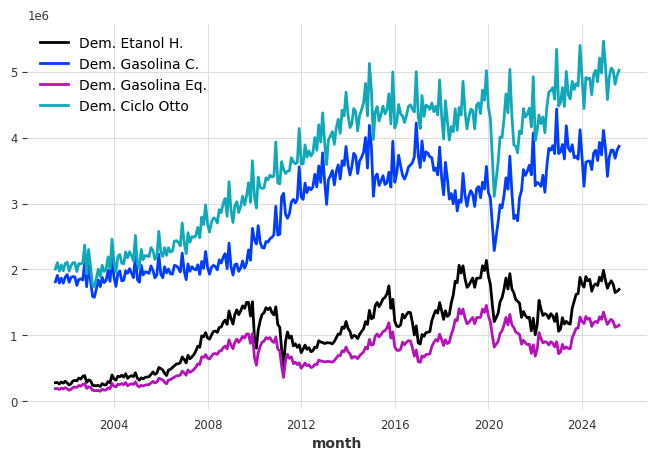

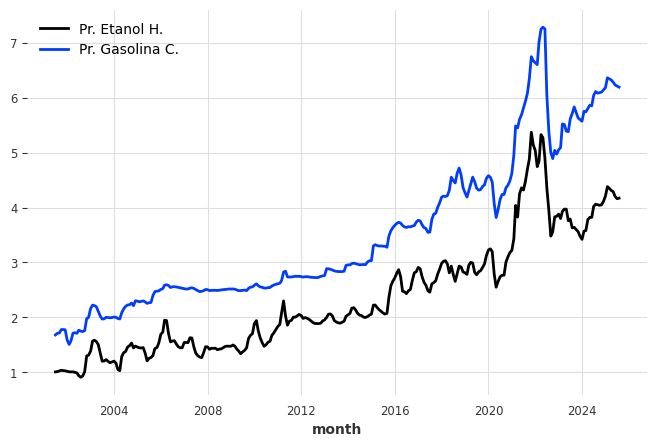

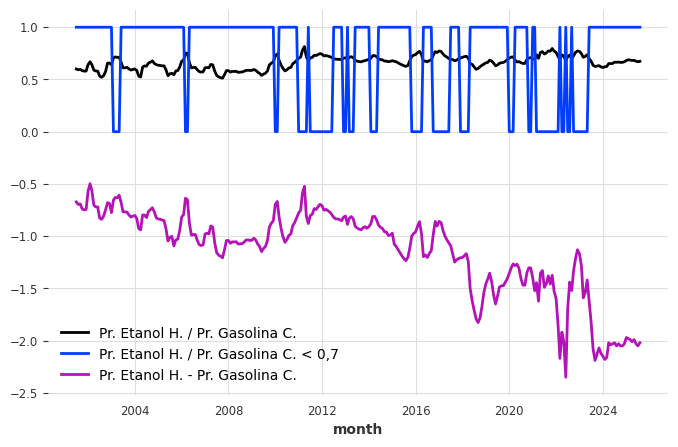

In [11]:
d_etanol_hid = TimeSeries.from_dataframe(df, "month", "Dem. Etanol H.", freq='MS')
d_gasolina_com = TimeSeries.from_dataframe(df, "month", "Dem. Gasolina C.", freq='MS')
d_gasolina_eq = TimeSeries.from_dataframe(df, "month", "Dem. Gasolina Eq.", freq='MS')
d_ciclo_otto = TimeSeries.from_dataframe(df, "month", "Dem. Ciclo Otto", freq='MS')
p_etanol_hid = TimeSeries.from_dataframe(df, "month", "Pr. Etanol H.", freq='MS')
p_gasolina_com = TimeSeries.from_dataframe(df, "month", "Pr. Gasolina C.", freq='MS')
p_r_etanol_gasolina = TimeSeries.from_dataframe(df, "month", "Pr. Etanol H. / Pr. Gasolina C.", freq='MS')
p_r_etanol_gasolina_bool = TimeSeries.from_dataframe(df, "month", "Pr. Etanol H. / Pr. Gasolina C. < 0,7", freq='MS')
p_d_etanol_gasolina = TimeSeries.from_dataframe(df, "month", "Pr. Etanol H. - Pr. Gasolina C.", freq='MS')

# Datas de início e fim da série completa
start_date = d_etanol_hid.start_time()
end_date = d_etanol_hid.end_time()

# Data final para treino+validação (dez/2024)
val_end = pd.Timestamp("2024-12-31")

# Série até dez/2024
train_val_series = d_etanol_hid.slice(start_date, val_end)

# Calcular índice de corte 70% treino / 30% validação
train_len = int(len(train_val_series) * 0.7)

# Datas correspondentes ao corte
train_start = train_val_series.start_time()
train_end = train_val_series.time_index[train_len - 1]  # último ponto do treino
VAL_START = train_end + pd.offsets.MonthBegin(1)        # mês seguinte
TEST_START = pd.Timestamp("2025-01-01")

plot_series(
    [
        d_etanol_hid,
        d_gasolina_com,
        d_gasolina_eq,
        d_ciclo_otto,
    ],
)
plot_series(
    [
        p_etanol_hid,
        p_gasolina_com,
    ],
)

plot_series(
    [
        p_r_etanol_gasolina,
        p_r_etanol_gasolina_bool,
        p_d_etanol_gasolina,
    ],
)

## Divisão dos conjuntos em treino, validação e teste

In [12]:
train, val, test = d_etanol_hid.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_d_gasolina, val_d_gasolina, test_d_gasolina = d_gasolina_com.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_d_gasolina_eq, val_d_gasolina_eq, test_d_gasolina_eq = d_gasolina_eq.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_d_ciclo_otto, val_d_ciclo_otto, test_d_ciclo_otto = d_ciclo_otto.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_p_etanol, val_p_etanol, test_p_etanol = p_etanol_hid.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_p_gasolina, val_p_gasolina, test_p_gasolina = p_gasolina_com.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_p_r_etanol_gasolina, val_p_r_etanol_gasolina, test_p_r_etanol_gasolina = p_r_etanol_gasolina.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_p_d_etanol_gasolina, val_p_d_etanol_gasolina, test_p_d_etanol_gasolina = p_d_etanol_gasolina.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)
train_p_r_etanol_gasolina_bool, val_p_r_etanol_gasolina_bool, test_p_r_etanol_gasolina_bool = p_r_etanol_gasolina_bool.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)

print(
    f"Treinamento: {train.time_index[0].strftime(DATE_FORMAT_STRING)} - {train.time_index[- 1].strftime(DATE_FORMAT_STRING)}"
)
print(
    f"Validação  : {val.time_index[0].strftime(DATE_FORMAT_STRING)} - {val.time_index[-1].strftime(DATE_FORMAT_STRING)}"
)
print(
    f"Teste      : {test.time_index[0].strftime(DATE_FORMAT_STRING)} - {test.time_index[-1].strftime(DATE_FORMAT_STRING)}"
)

Treinamento: 01/07/2001 - 01/11/2017
Validação  : 01/12/2017 - 01/12/2024
Teste      : 01/01/2025 - 01/08/2025


## Tratamento de dados - Série original

#### Verificação da sazonalidade

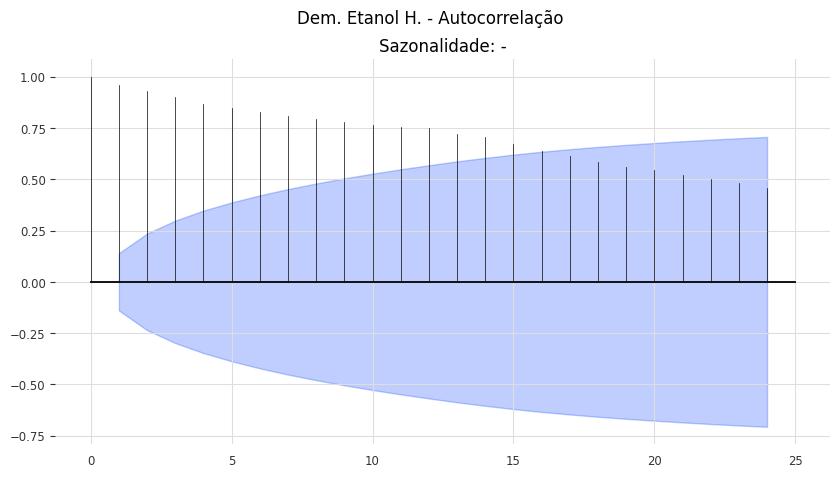

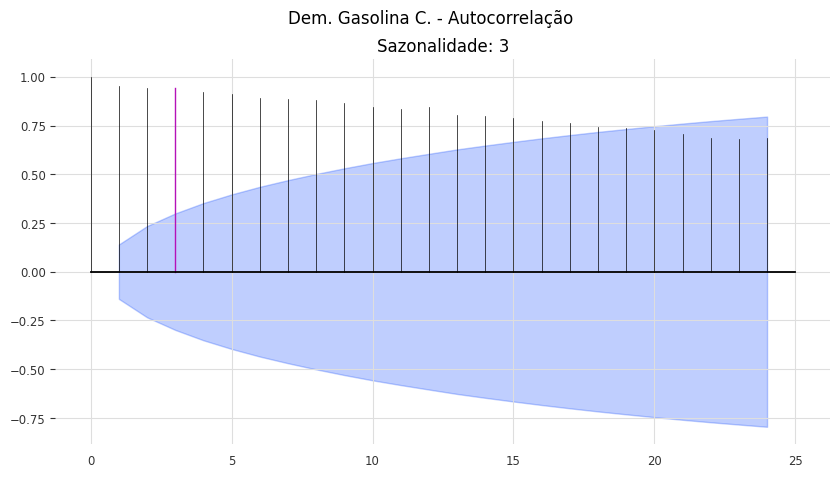

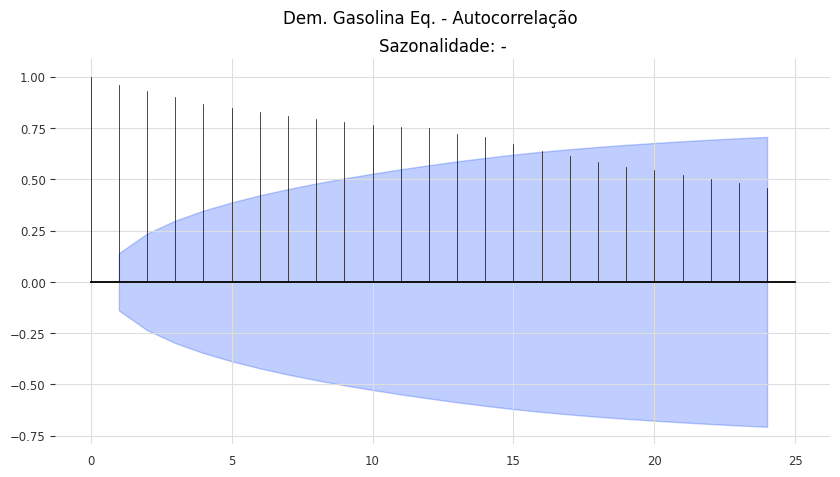

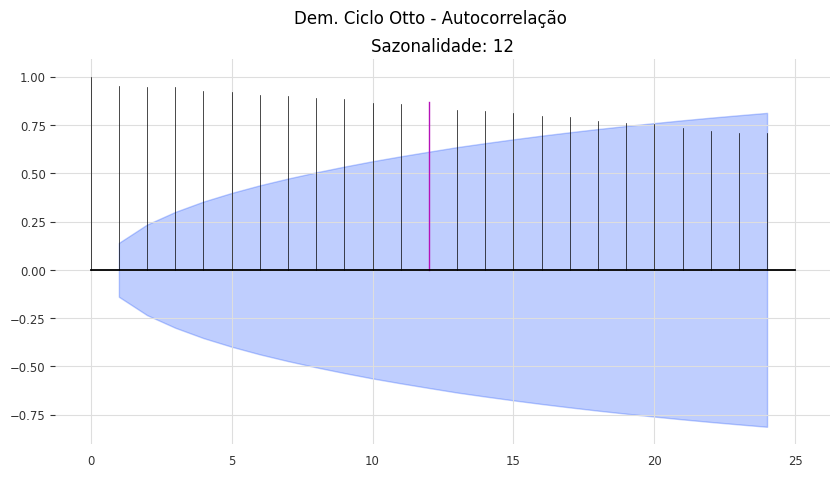

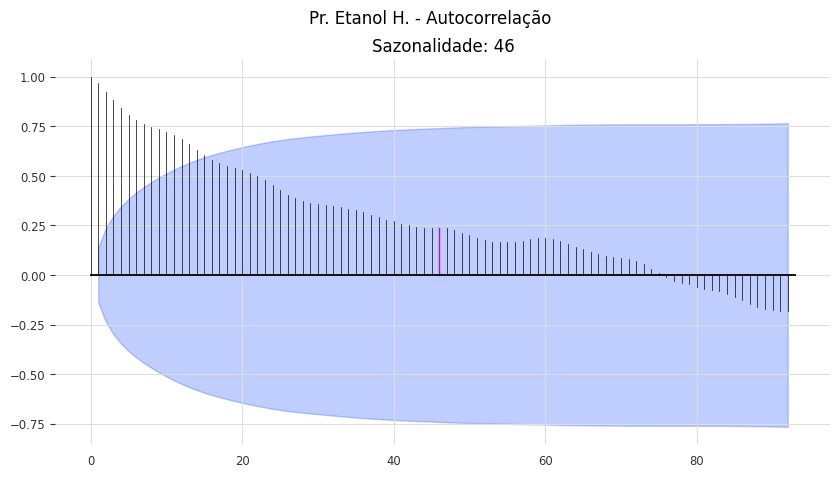

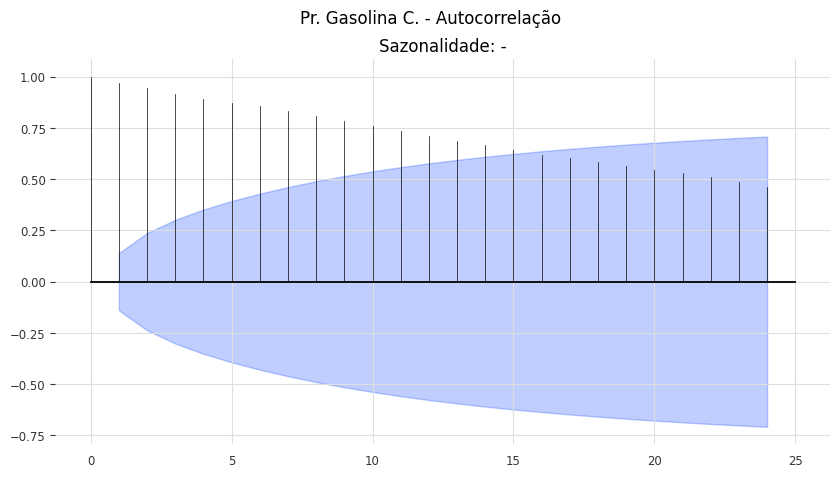

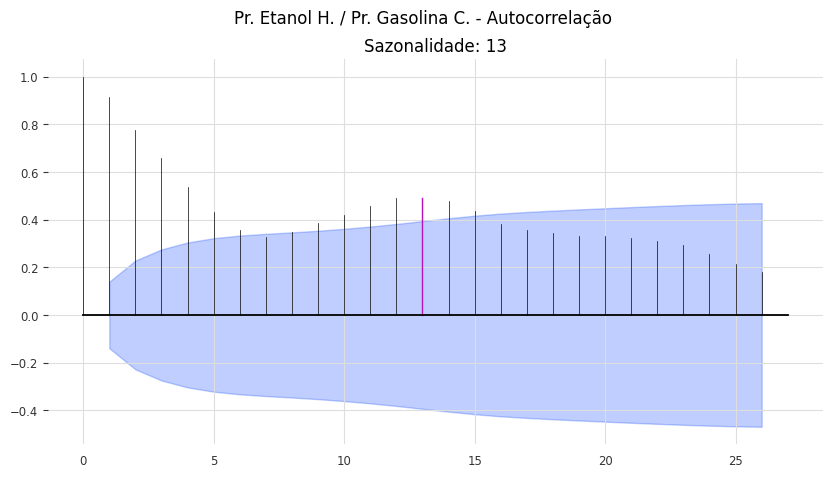

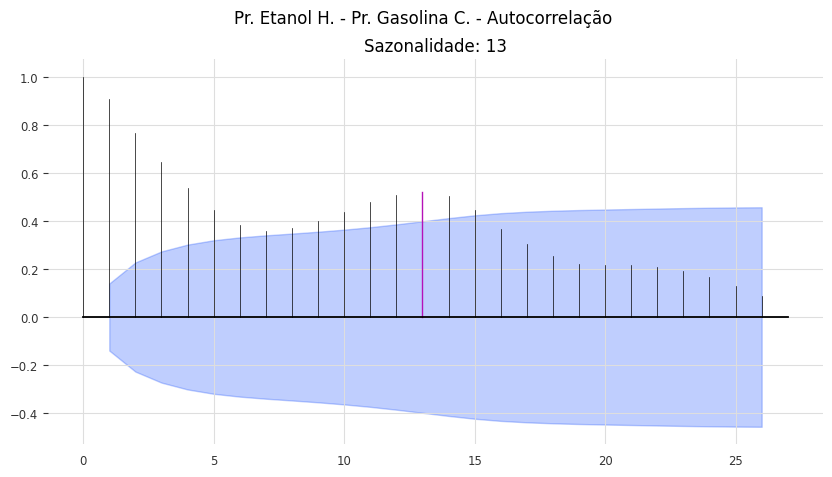

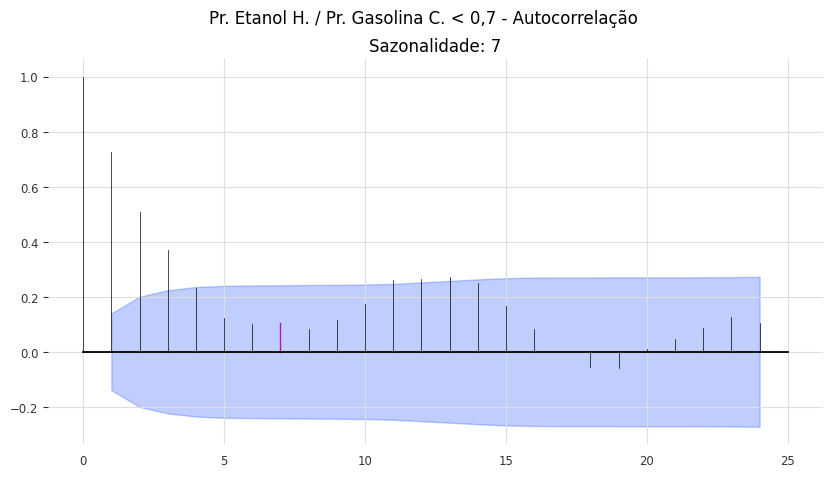

In [13]:
train.plot_acf()
train_d_gasolina.plot_acf()
train_d_gasolina_eq.plot_acf()
train_d_ciclo_otto.plot_acf()
train_p_etanol.plot_acf()
train_p_gasolina.plot_acf()
train_p_r_etanol_gasolina.plot_acf()
train_p_d_etanol_gasolina.plot_acf()
train_p_r_etanol_gasolina_bool.plot_acf()

#### Verificação de ciclos

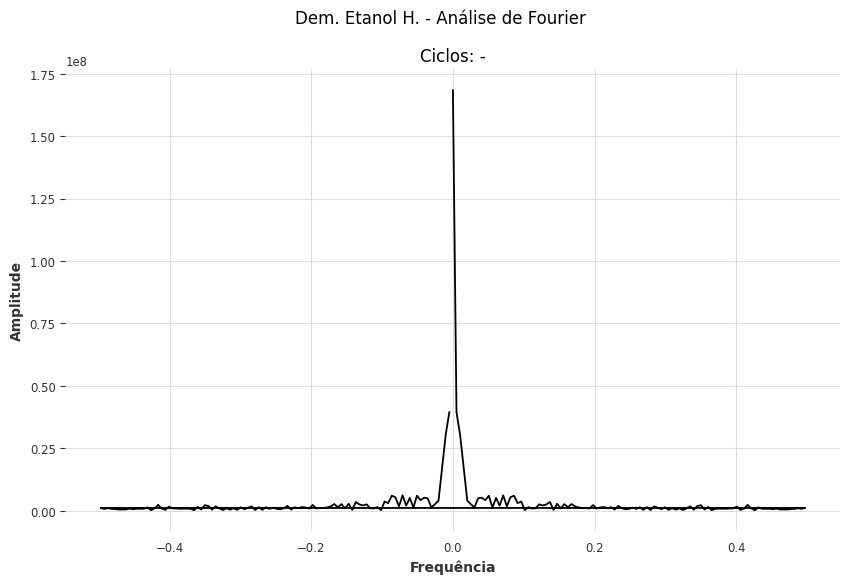

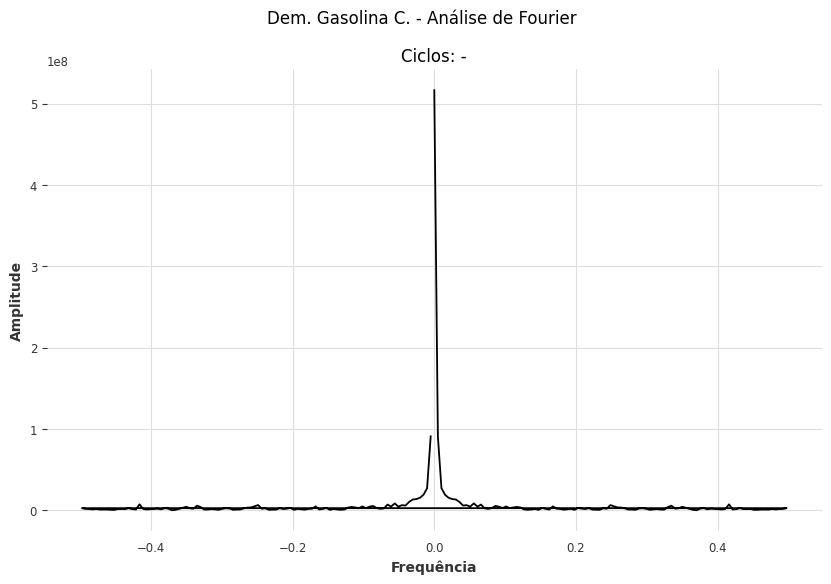

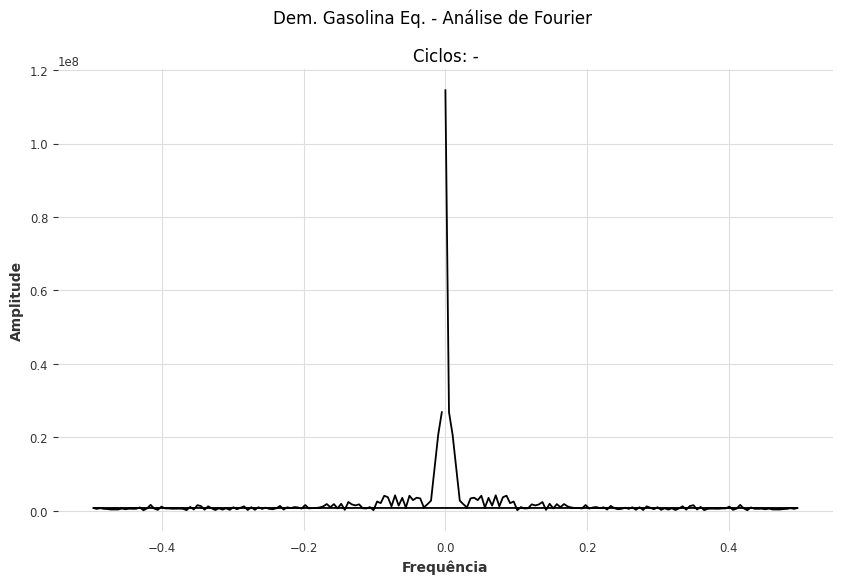

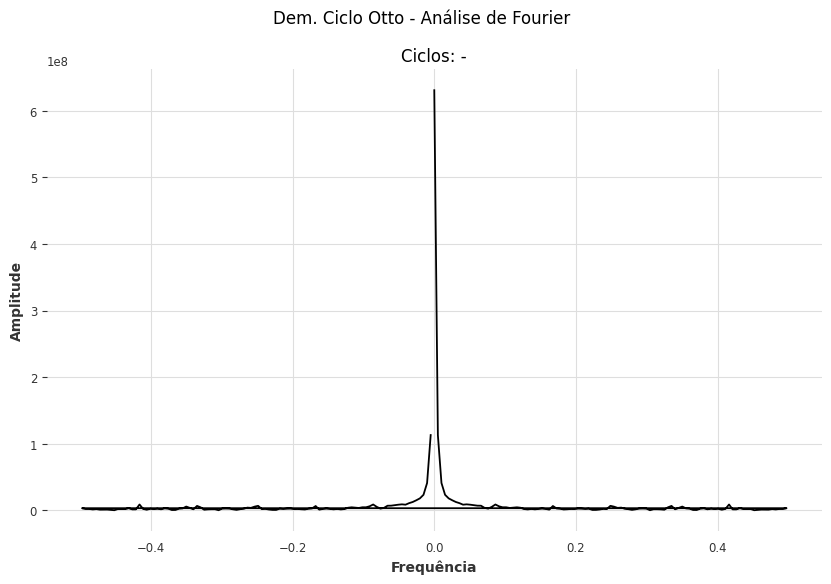

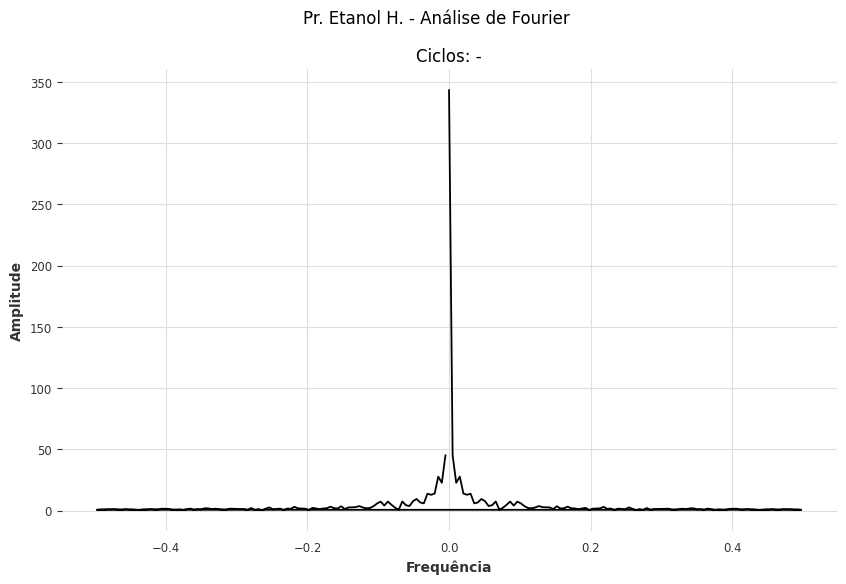

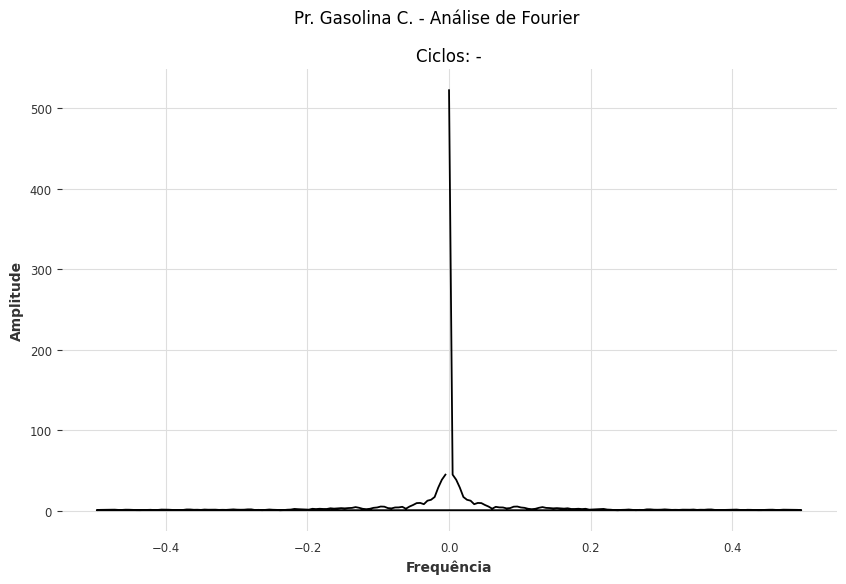

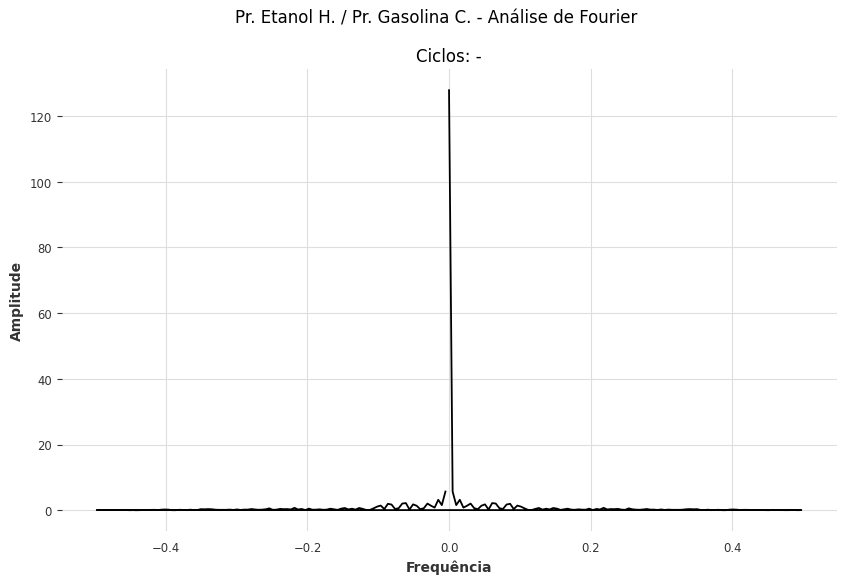

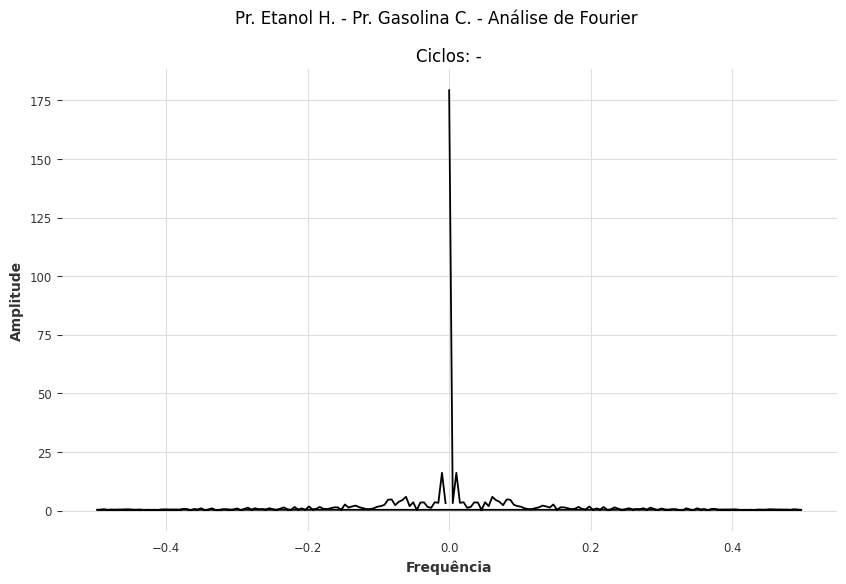

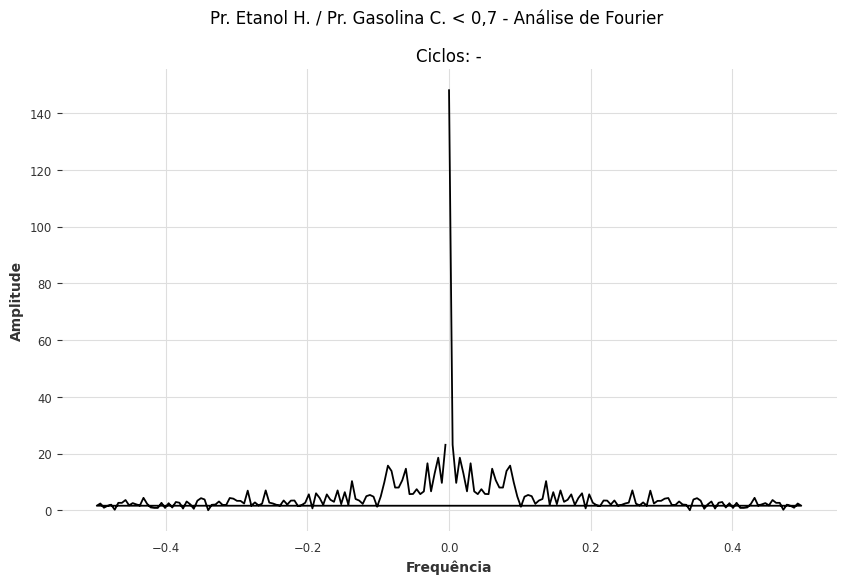

In [14]:
train.plot_fourier_analisys()
train_d_gasolina.plot_fourier_analisys()
train_d_gasolina_eq.plot_fourier_analisys()
train_d_ciclo_otto.plot_fourier_analisys()
train_p_etanol.plot_fourier_analisys()
train_p_gasolina.plot_fourier_analisys()
train_p_r_etanol_gasolina.plot_fourier_analisys()
train_p_d_etanol_gasolina.plot_fourier_analisys()
train_p_r_etanol_gasolina_bool.plot_fourier_analisys()

#### Coeficiente de Hurst

In [15]:
hurst = Hurst()

H, HDescription = hurst.calculate(train)
print("Coeficiente de Hurst = {:.2f} - {}".format(H, HDescription))

Coeficiente de Hurst = 0.39 - Anti-persistente


#### Matriz de correlação

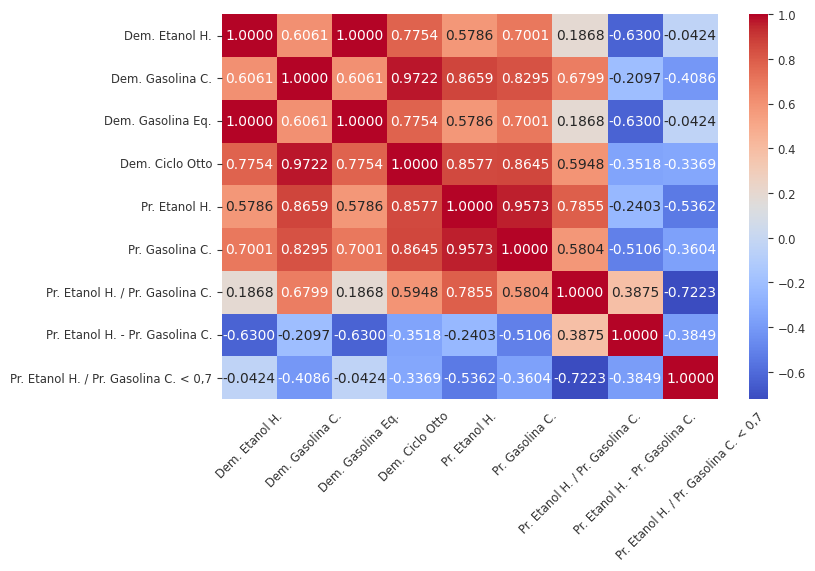

array([[ 1.        ,  0.60612157,  1.        ,  0.77538748,  0.57859148,
         0.70008453,  0.18684387, -0.63001784, -0.04239067],
       [ 0.60612157,  1.        ,  0.60612157,  0.97224517,  0.86592871,
         0.82946634,  0.67994008, -0.20970602, -0.40858251],
       [ 1.        ,  0.60612157,  1.        ,  0.77538748,  0.57859148,
         0.70008453,  0.18684387, -0.63001784, -0.04239067],
       [ 0.77538748,  0.97224517,  0.77538748,  1.        ,  0.85770108,
         0.86448982,  0.5948    , -0.35182039, -0.33686367],
       [ 0.57859148,  0.86592871,  0.57859148,  0.85770108,  1.        ,
         0.95732732,  0.78545719, -0.24027746, -0.53623334],
       [ 0.70008453,  0.82946634,  0.70008453,  0.86448982,  0.95732732,
         1.        ,  0.58037896, -0.51056342, -0.36038327],
       [ 0.18684387,  0.67994008,  0.18684387,  0.5948    ,  0.78545719,
         0.58037896,  1.        ,  0.38750511, -0.72228002],
       [-0.63001784, -0.20970602, -0.63001784, -0.35182039, -0

In [16]:
plot_correlation_matrix([
    train,
    train_d_gasolina,
    train_d_gasolina_eq,
    train_d_ciclo_otto,
    train_p_etanol,
    train_p_gasolina,
    train_p_r_etanol_gasolina,
    train_p_d_etanol_gasolina,
    train_p_r_etanol_gasolina_bool,
], annot = True, fmt=".4f", )

#### Matriz de informação mutua

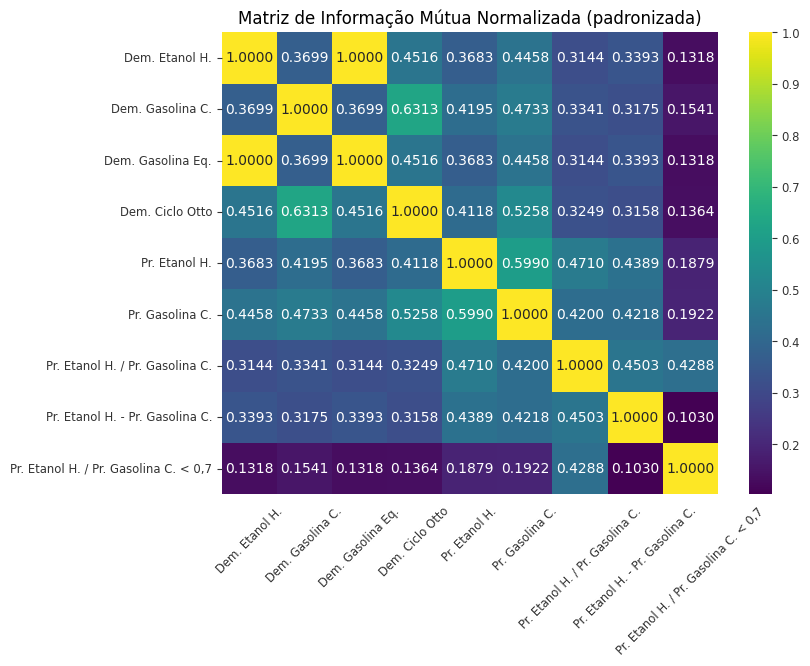

array([[1.        , 0.3699362 , 1.        , 0.45160176, 0.36831574,
        0.44580647, 0.31444644, 0.33933645, 0.13184064],
       [0.3699362 , 1.        , 0.3699362 , 0.63130683, 0.41947444,
        0.473307  , 0.33405121, 0.3175038 , 0.15407605],
       [1.        , 0.3699362 , 1.        , 0.45160176, 0.36831574,
        0.44580647, 0.31444644, 0.33933645, 0.13184064],
       [0.45160176, 0.63130683, 0.45160176, 1.        , 0.41176547,
        0.52584835, 0.32491379, 0.31575802, 0.13640101],
       [0.36831574, 0.41947444, 0.36831574, 0.41176547, 1.        ,
        0.59901975, 0.47096203, 0.43885144, 0.18790841],
       [0.44580647, 0.473307  , 0.44580647, 0.52584835, 0.59901975,
        1.        , 0.41999889, 0.42178405, 0.19218593],
       [0.31444644, 0.33405121, 0.31444644, 0.32491379, 0.47096203,
        0.41999889, 1.        , 0.45025963, 0.42877332],
       [0.33933645, 0.3175038 , 0.33933645, 0.31575802, 0.43885144,
        0.42178405, 0.45025963, 1.        , 0.10299309],


In [17]:
plot_mutual_information_matrix([
    train,
    train_d_gasolina,
    train_d_gasolina_eq,
    train_d_ciclo_otto,
    train_p_etanol,
    train_p_gasolina,
    train_p_r_etanol_gasolina,
    train_p_d_etanol_gasolina,
    train_p_r_etanol_gasolina_bool,
], annot = True, fmt=".4f", )

### Seleção de features

In [18]:
import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression, mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mutual_info_score

# =======================================================
# Funções auxiliares
# =======================================================

def entropy(x_binned):
    """Calcula entropia de vetor discretizado."""
    probs, _ = np.histogram(x_binned, bins=np.unique(x_binned).size)
    probs = probs[probs > 0] / np.sum(probs)
    return -np.sum(probs * np.log(probs))

def mutual_information_matrix(X, n_bins=20):
    """Matriz de informação mútua entre features."""
    cols = X.columns
    n = len(cols)
    all_values = X.values.ravel()
    bins = np.histogram_bin_edges(all_values, bins=n_bins)
    X_binned = [np.digitize(X[c].values, bins) for c in cols]

    H = [entropy(xb) for xb in X_binned]
    MI = np.zeros((n, n))

    for i in range(n):
        for j in range(i, n):
            mi = mutual_info_score(X_binned[i], X_binned[j])
            if H[i] > 0 and H[j] > 0:
                nmi = mi / np.sqrt(H[i] * H[j])
            else:
                nmi = 0
            MI[i, j] = MI[j, i] = nmi
    return pd.DataFrame(MI, index=cols, columns=cols)


def select_features_mrmr(X, y, num_features=10, classification=False, n_bins=20):
    """
    Seleciona variáveis com base em mRMR (máxima relevância, mínima redundância).
    Retorna uma lista com as melhores features.
    """
    # Padroniza para evitar distorções de escala
    X_scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)

    # 1️⃣ Relevância: MI com o alvo
    if classification:
        relevance = mutual_info_classif(X_scaled, y, discrete_features=False)
    else:
        relevance = mutual_info_regression(X_scaled, y, discrete_features=False)
    relevance = pd.Series(relevance, index=X.columns)

    # 2️⃣ Redundância: média da MI entre features
    mi_matrix = mutual_information_matrix(X_scaled, n_bins=n_bins)
    redundancy = mi_matrix.mean(axis=1)

    # 3️⃣ Score mRMR: relevância - redundância
    mrmr_score = relevance - redundancy
    ranked_features = mrmr_score.sort_values(ascending=False)

    print("\n===== Ranking de Features (mRMR) =====")
    print(ranked_features.head(num_features))

    return ranked_features.head(num_features).index.tolist(), ranked_features


# =======================================================
# Exemplo de uso
# =======================================================


X = df
y = df['Dem. Etanol H.']

best_features, ranking = select_features_mrmr(X, y, num_features=5)

print("\nMelhores variáveis selecionadas:", best_features)


DTypePromotionError: The DType <class 'numpy.dtypes.DateTime64DType'> could not be promoted by <class 'numpy.dtypes.Float64DType'>. This means that no common DType exists for the given inputs. For example they cannot be stored in a single array unless the dtype is `object`. The full list of DTypes is: (<class 'numpy.dtypes.DateTime64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.BoolDType'>)

### Aplicando o filtro de média móvel

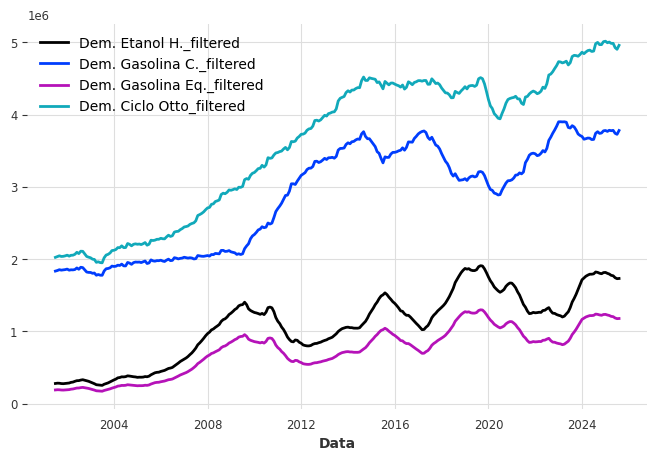

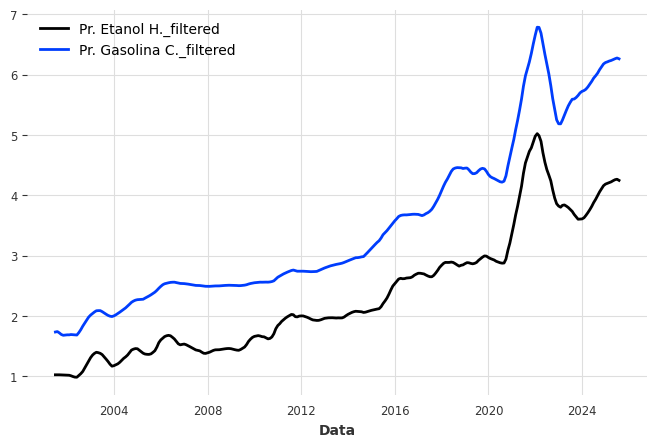

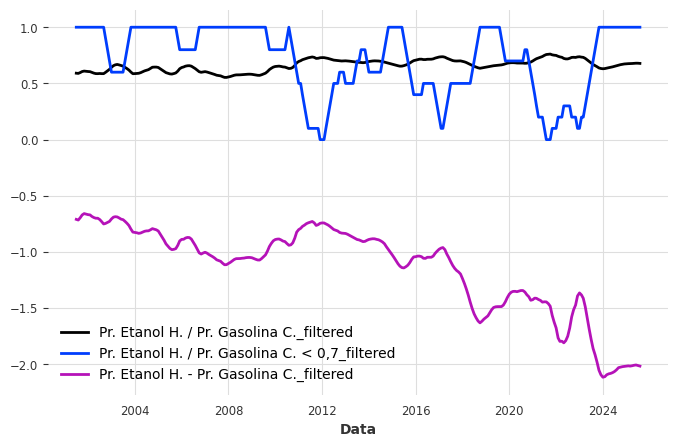

In [19]:
d_etanol_hid_filtered = d_etanol_hid.filter()[0]
d_gasolina_com_filtered = d_gasolina_com.filter()[0]
d_gasolina_eq_filtered = d_gasolina_eq.filter()[0]
d_ciclo_otto_filtered = d_ciclo_otto.filter()[0]
p_etanol_hid_filtered = p_etanol_hid.filter()[0]
p_gasolina_com_filtered = p_gasolina_com.filter()[0]
p_r_etanol_gasolina_filtered = p_r_etanol_gasolina.filter()[0]
p_r_etanol_gasolina_bool_filtered = p_r_etanol_gasolina_bool.filter()[0]
p_d_etanol_gasolina_filtered = p_d_etanol_gasolina.filter()[0]

plot_series(
    [
        d_etanol_hid_filtered,
        d_gasolina_com_filtered,
        d_gasolina_eq_filtered,
        d_ciclo_otto_filtered,
    ],
)
plot_series(
    [
        p_etanol_hid_filtered,
        p_gasolina_com_filtered,
    ],
)

plot_series(
    [
        p_r_etanol_gasolina_filtered,
        p_r_etanol_gasolina_bool_filtered,
        p_d_etanol_gasolina_filtered,
    ],
)

## Tratamento de dados - Série sem tendência

In [20]:
# --- Supondo que sua classe Detrend já está definida ---
scaler = Detrend()

# --- Função auxiliar para detrend e reconstruir TimeSeries ---
def detrend_series(train, val, test, series):
    # Nome do componente original
    component_name = series.columns[0]

    scaler = Detrend()

    # Extrair numpy univariado
    train_np = train.univariate_component(0).values()[:,0]
    val_np = val.univariate_component(0).values()[:,0]
    test_np = test.univariate_component(0).values()[:,0]
    series_np = series.univariate_component(0).values()[:,0]

    # Fit e transform no treino
    train_detrend_np = scaler.fit_transform(train_np)
    val_detrend_np = scaler.transform(val_np)
    test_detrend_np = scaler.transform(test_np)
    series_detrend_np = scaler.transform(series_np)

    # Reconstruir TimeSeries mantendo time_index
    train_detrend = TimeSeries.from_times_and_values(train.time_index, train_detrend_np.reshape(-1,1), columns=[component_name])
    val_detrend = TimeSeries.from_times_and_values(val.time_index, val_detrend_np.reshape(-1,1), columns=[component_name])
    test_detrend = TimeSeries.from_times_and_values(test.time_index, test_detrend_np.reshape(-1,1), columns=[component_name])
    series_detrend = TimeSeries.from_times_and_values(series.time_index, series_detrend_np.reshape(-1,1), columns=[component_name])

    return train_detrend, val_detrend, test_detrend, series_detrend


train_detrend, val_detrend, test_detrend, d_etanol_hid_detrend = detrend_series(train, val, test, d_etanol_hid)
train_d_gasolina_detrend, val_d_gasolina_detrend, test_d_gasolina_detrend, d_gasolina_com_detrend = detrend_series(train_d_gasolina, val_d_gasolina, test_d_gasolina, d_gasolina_com)
train_d_gasolina_eq_detrend, val_d_gasolina_eq_detrend, test_d_gasolina_eq_detrend, d_gasolina_eq_detrend = detrend_series(train_d_gasolina_eq, val_d_gasolina_eq, test_d_gasolina_eq, d_gasolina_eq)
train_d_ciclo_otto_detrend, val_d_ciclo_otto_detrend, test_d_ciclo_otto_detrend, d_ciclo_otto_detrend = detrend_series(train_d_ciclo_otto, val_d_ciclo_otto, test_d_ciclo_otto, d_ciclo_otto)
train_p_etanol_detrend, val_p_etanol_detrend, test_p_etanol_detrend, p_etanol_hid_detrend = detrend_series(train_p_etanol, val_p_etanol, test_p_etanol, p_etanol_hid)
train_p_gasolina_detrend, val_p_gasolina_detrend, test_p_gasolina_detrend, p_gasolina_com_detrend = detrend_series(train_p_gasolina, val_p_gasolina, test_p_gasolina, p_gasolina_com)
train_p_r_etanol_gasolina_detrend, val_p_r_etanol_gasolina_detrend, test_p_r_etanol_gasolina_detrend, p_r_etanol_gasolina_detrend = detrend_series(train_p_r_etanol_gasolina, val_p_r_etanol_gasolina, test_p_r_etanol_gasolina, p_r_etanol_gasolina)
train_p_d_etanol_gasolina_detrend, val_p_d_etanol_gasolina_detrend, test_p_d_etanol_gasolina_detrend, p_d_etanol_gasolina_detrend = detrend_series(train_p_d_etanol_gasolina, val_p_d_etanol_gasolina, test_p_d_etanol_gasolina, p_d_etanol_gasolina)
train_p_r_etanol_gasolina_bool_detrend, val_p_r_etanol_gasolina_bool_detrend, test_p_r_etanol_gasolina_bool_detrend, p_r_etanol_gasolina_bool_detrend = detrend_series(train_p_r_etanol_gasolina_bool, val_p_r_etanol_gasolina_bool, test_p_r_etanol_gasolina_bool, p_r_etanol_gasolina_bool)

#### Verificação da sazonalidade

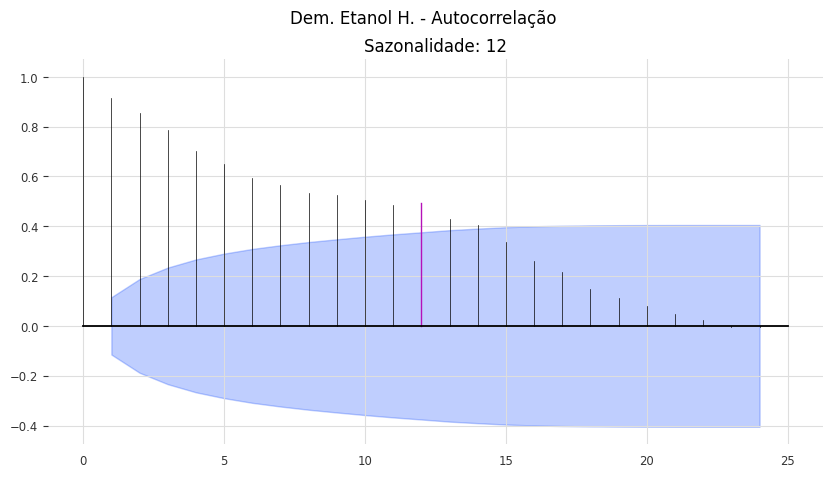

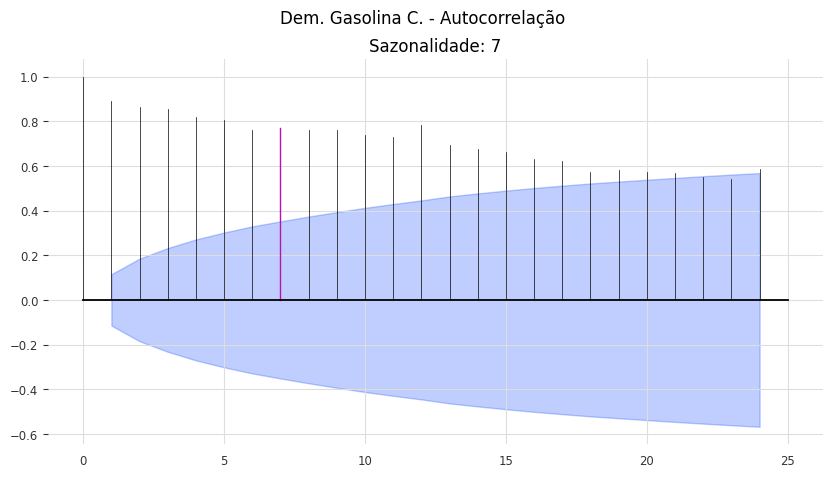

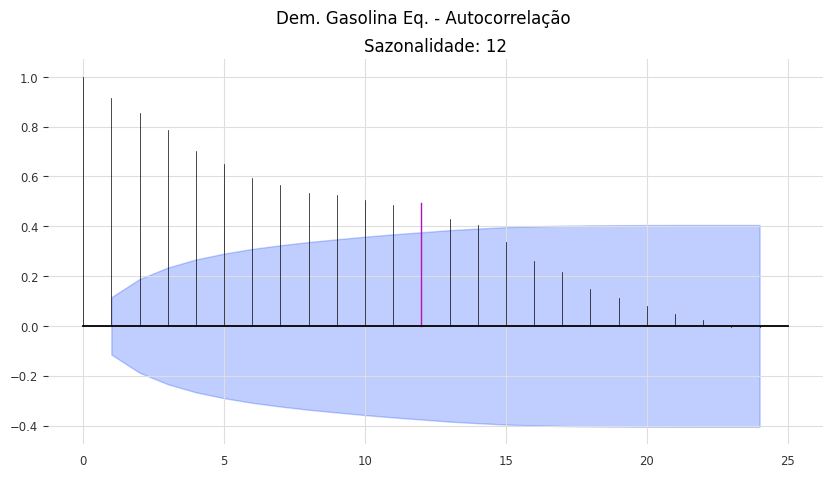

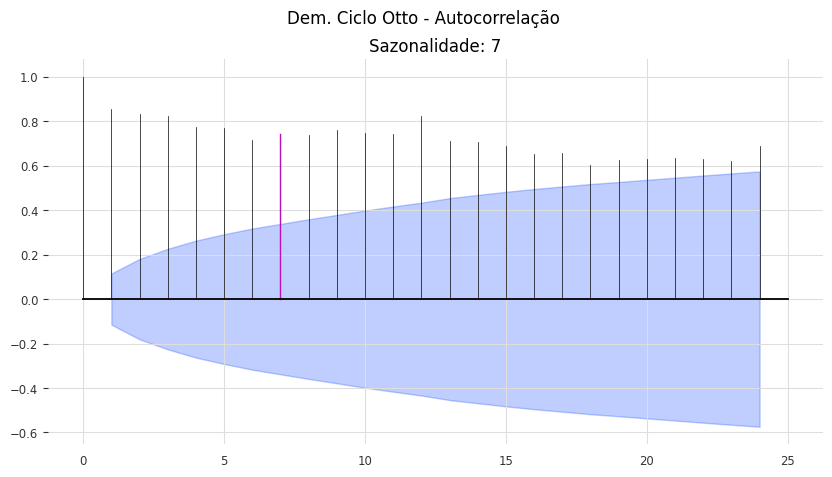

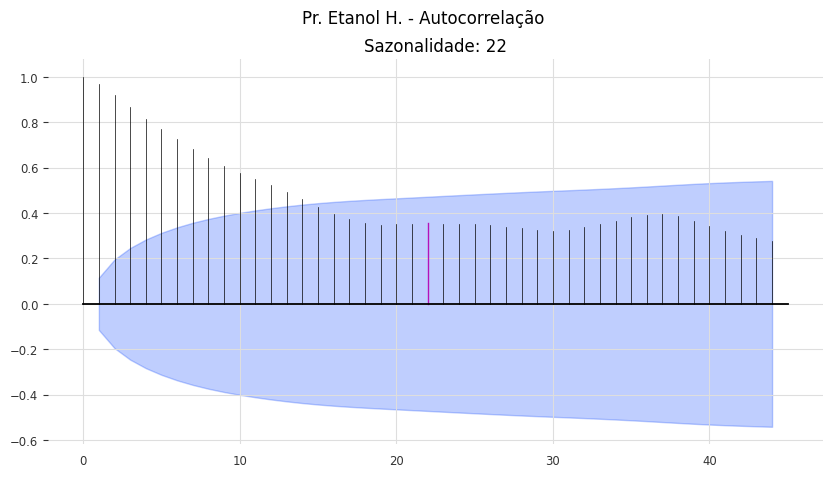

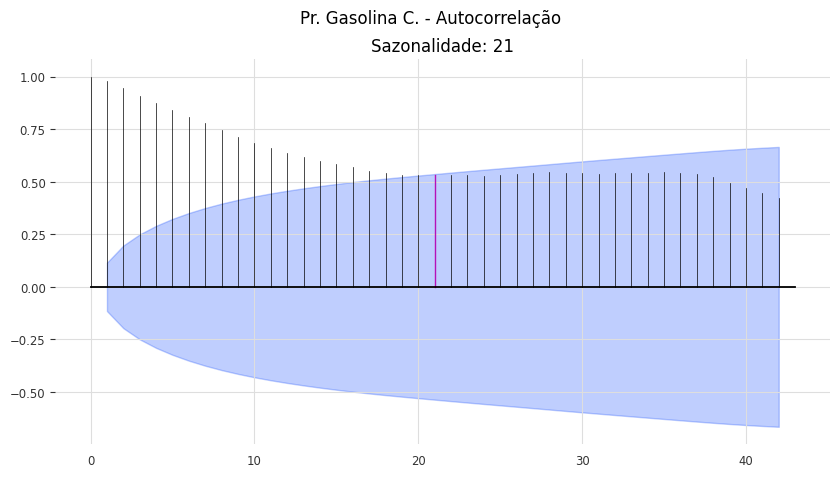

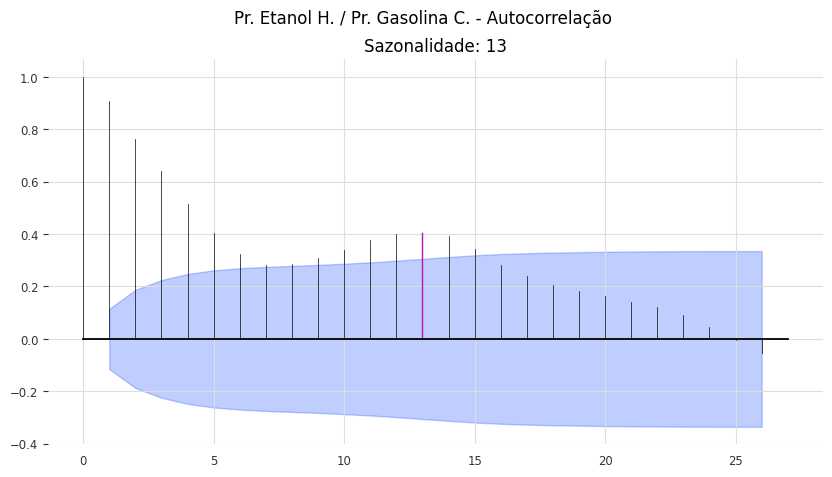

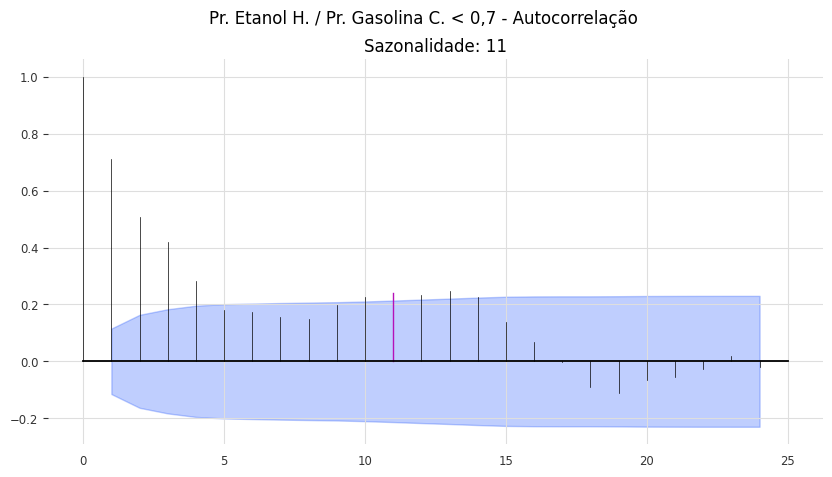

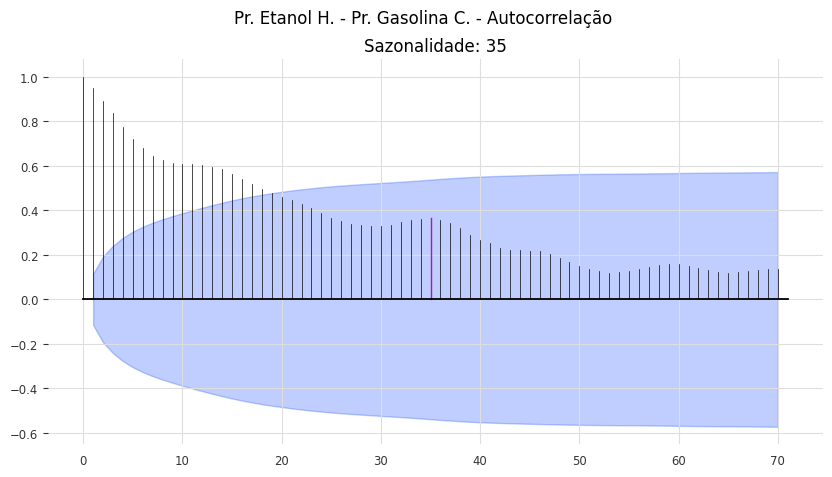

In [21]:
d_etanol_hid_detrend.plot_acf()
d_gasolina_com_detrend.plot_acf()
d_gasolina_eq_detrend.plot_acf()
d_ciclo_otto_detrend.plot_acf()
p_etanol_hid_detrend.plot_acf()
p_gasolina_com_detrend.plot_acf()
p_r_etanol_gasolina_detrend.plot_acf()
p_r_etanol_gasolina_bool_detrend.plot_acf()
p_d_etanol_gasolina_detrend.plot_acf()

#### Verificação de ciclos

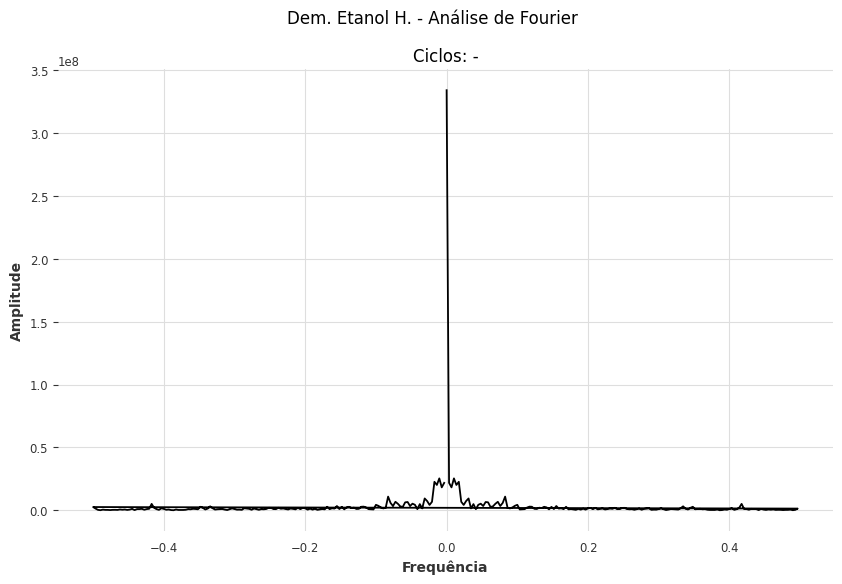

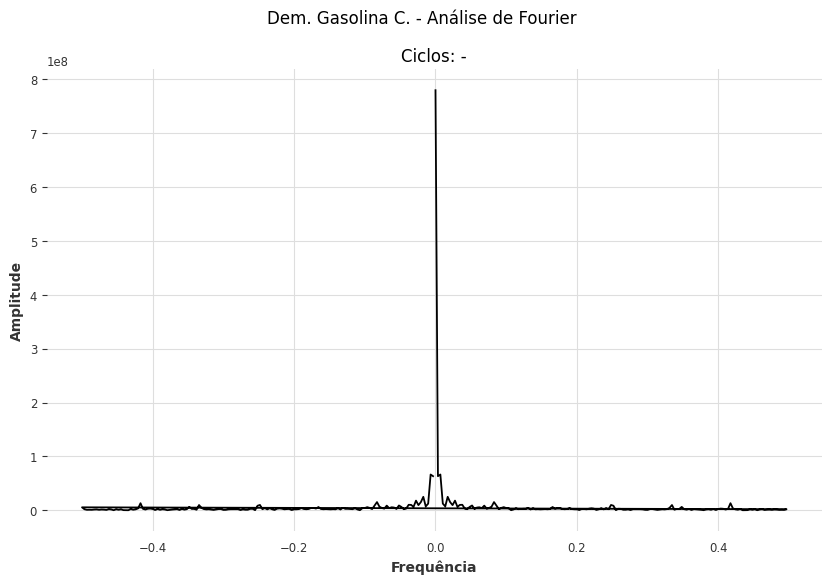

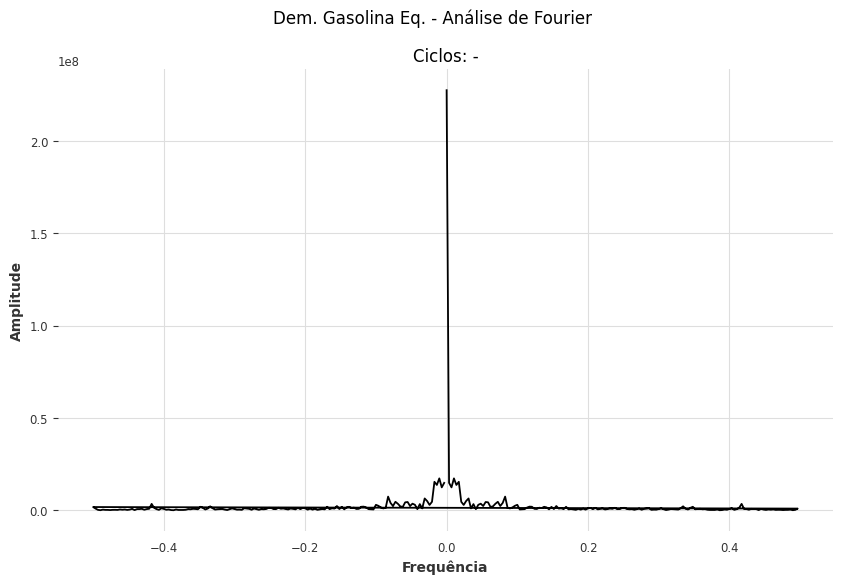

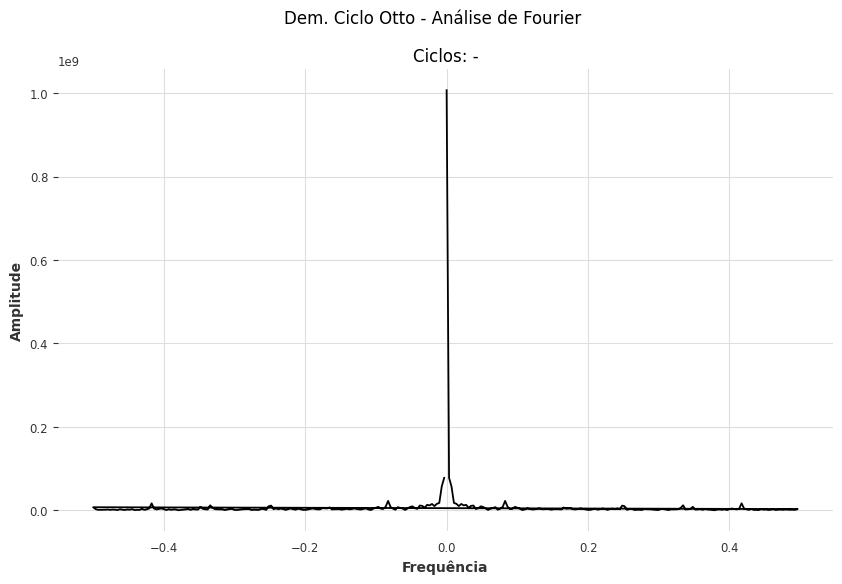

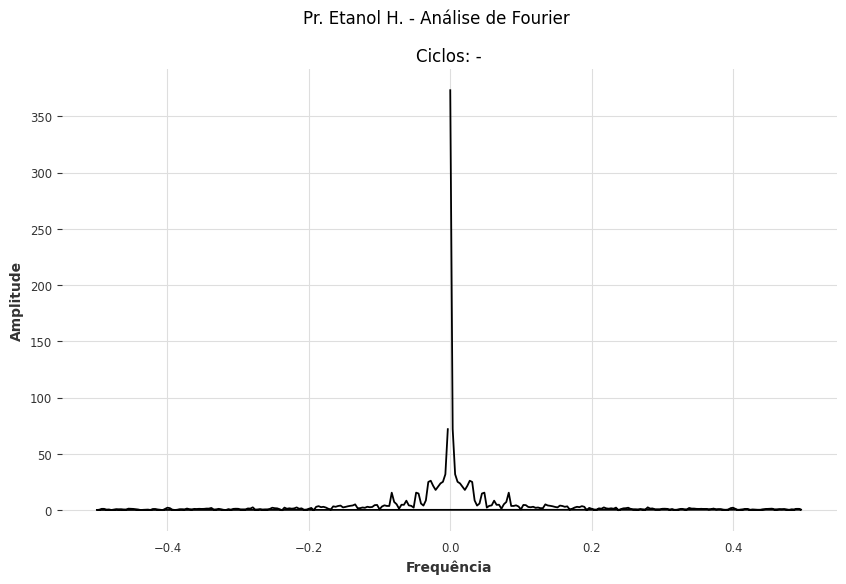

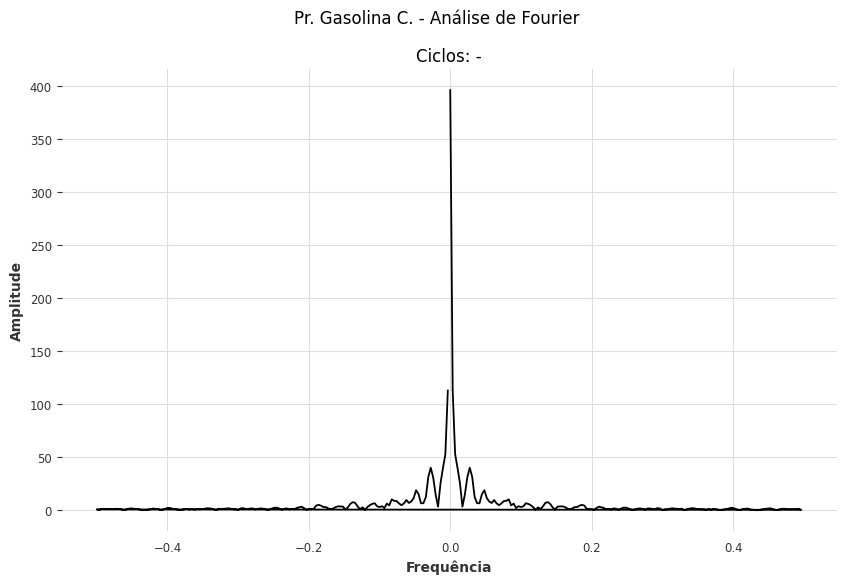

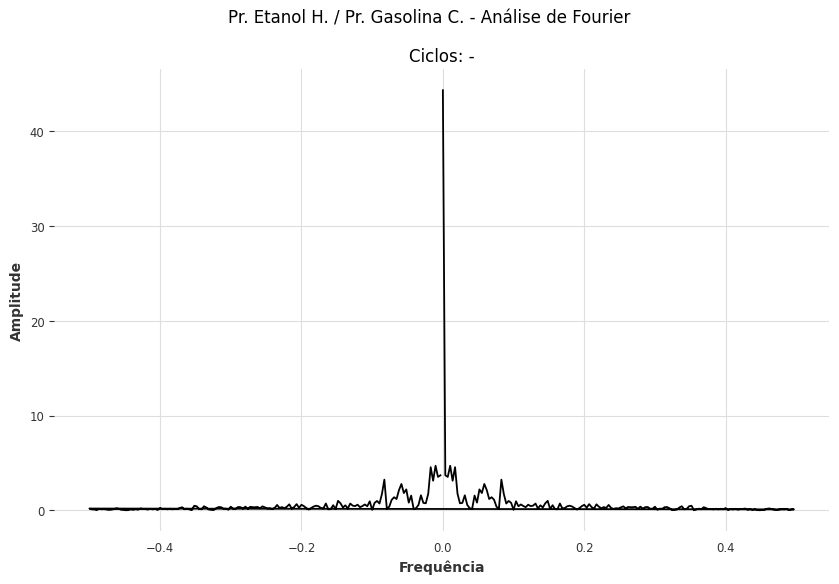

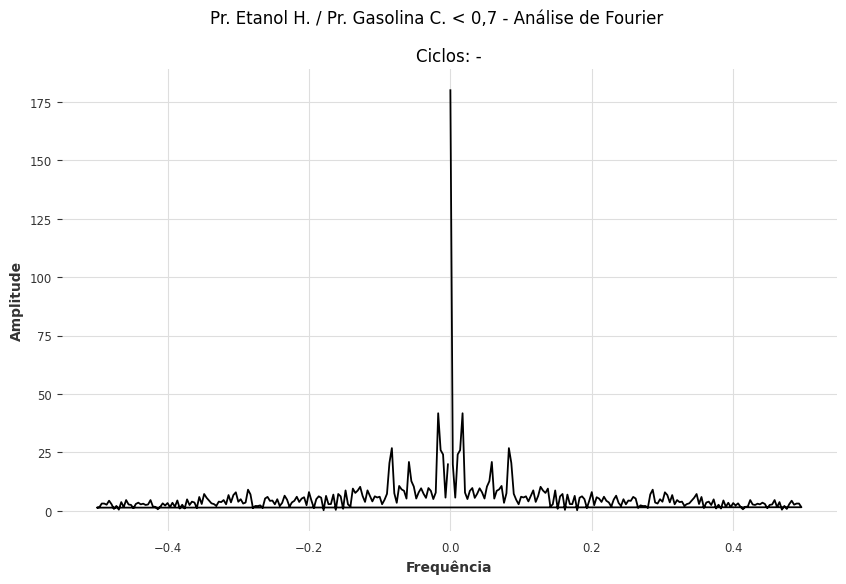

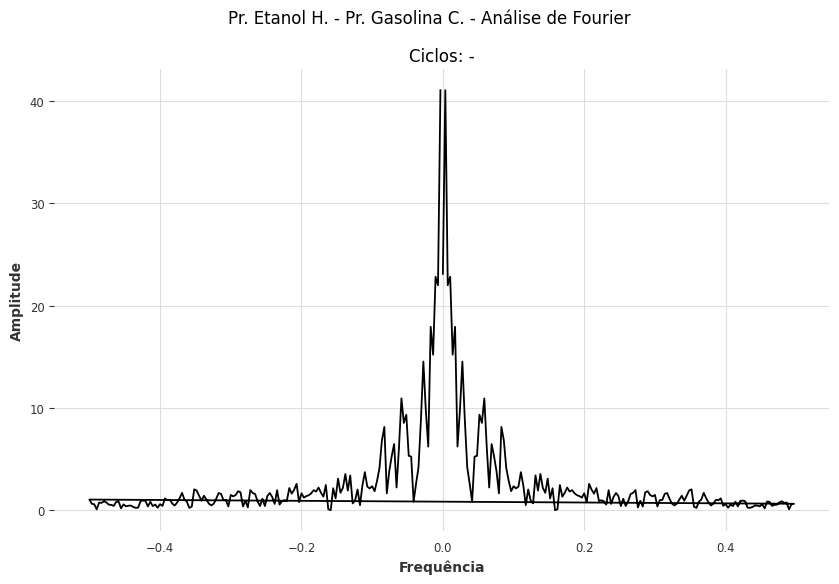

In [22]:
d_etanol_hid_detrend.plot_fourier_analisys()
d_gasolina_com_detrend.plot_fourier_analisys()
d_gasolina_eq_detrend.plot_fourier_analisys()
d_ciclo_otto_detrend.plot_fourier_analisys()
p_etanol_hid_detrend.plot_fourier_analisys()
p_gasolina_com_detrend.plot_fourier_analisys()
p_r_etanol_gasolina_detrend.plot_fourier_analisys()
p_r_etanol_gasolina_bool_detrend.plot_fourier_analisys()
p_d_etanol_gasolina_detrend.plot_fourier_analisys()

#### Coeficiente de Hurst

In [23]:
hurst = Hurst()

H, HDescription = hurst.calculate(d_etanol_hid_detrend)
print("Coeficiente de Hurst = {:.2f} - {}".format(H, HDescription))

Coeficiente de Hurst = 0.41 - Anti-persistente


#### Matriz de correlação

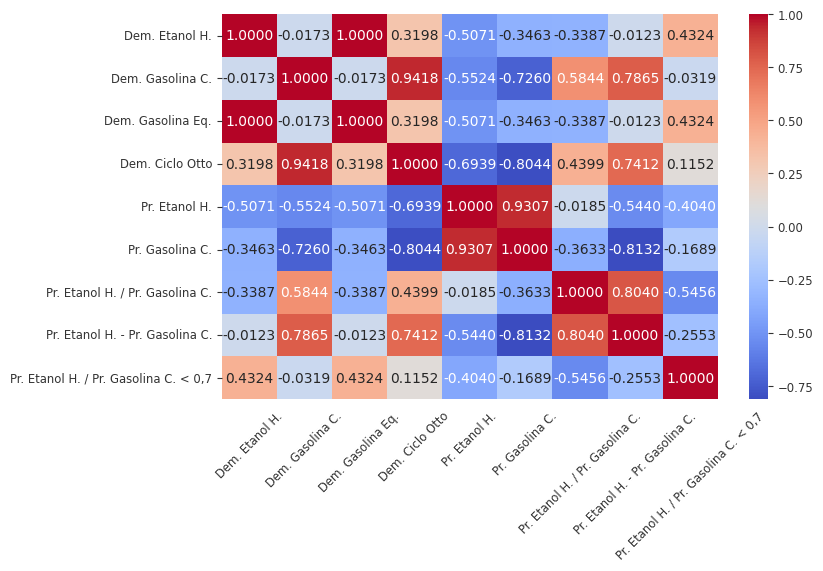

array([[ 1.        , -0.01731909,  1.        ,  0.31977174, -0.50707293,
        -0.34632391, -0.33871406, -0.01233782,  0.43236216],
       [-0.01731909,  1.        , -0.01731909,  0.94181434, -0.5523929 ,
        -0.7259745 ,  0.58441698,  0.78652357, -0.03185837],
       [ 1.        , -0.01731909,  1.        ,  0.31977174, -0.50707293,
        -0.34632391, -0.33871406, -0.01233782,  0.43236216],
       [ 0.31977174,  0.94181434,  0.31977174,  1.        , -0.69393759,
        -0.80438865,  0.43994478,  0.74119085,  0.11516306],
       [-0.50707293, -0.5523929 , -0.50707293, -0.69393759,  1.        ,
         0.93071158, -0.01850313, -0.54398682, -0.40398168],
       [-0.34632391, -0.7259745 , -0.34632391, -0.80438865,  0.93071158,
         1.        , -0.3632795 , -0.8131967 , -0.16891193],
       [-0.33871406,  0.58441698, -0.33871406,  0.43994478, -0.01850313,
        -0.3632795 ,  1.        ,  0.80397474, -0.54561149],
       [-0.01233782,  0.78652357, -0.01233782,  0.74119085, -0

In [24]:
plot_correlation_matrix([
    d_etanol_hid_detrend,
    d_gasolina_com_detrend,
    d_gasolina_eq_detrend,
    d_ciclo_otto_detrend,
    p_etanol_hid_detrend,
    p_gasolina_com_detrend,
    p_r_etanol_gasolina_detrend,
    p_d_etanol_gasolina_detrend,
    p_r_etanol_gasolina_bool,
], annot = True, fmt=".4f", )

#### Matriz de informação mutua

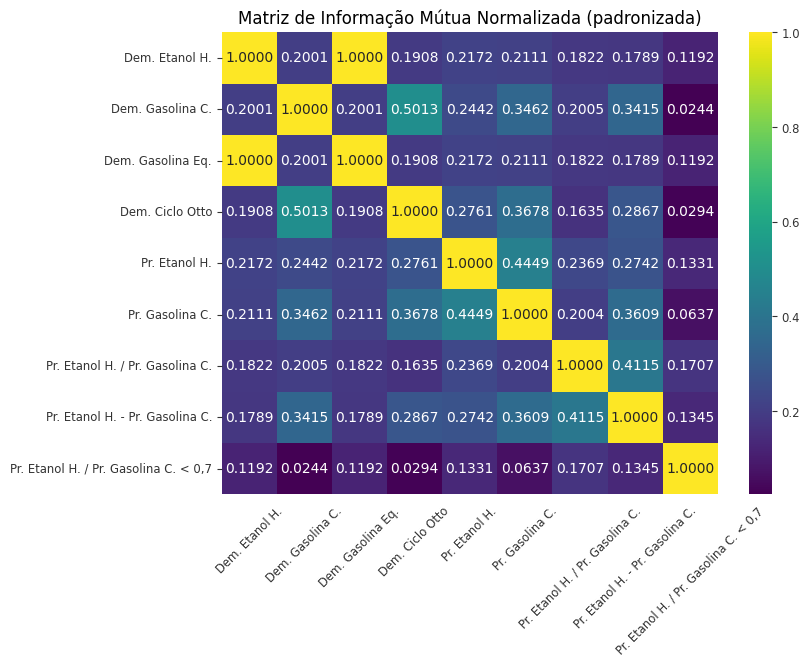

array([[1.        , 0.20006433, 1.        , 0.19084848, 0.21722771,
        0.21114982, 0.18218491, 0.17893183, 0.11924806],
       [0.20006433, 1.        , 0.20006433, 0.501346  , 0.24424229,
        0.34623643, 0.20054437, 0.34150697, 0.02435098],
       [1.        , 0.20006433, 1.        , 0.19084848, 0.21722771,
        0.21114982, 0.18218491, 0.17893183, 0.11924806],
       [0.19084848, 0.501346  , 0.19084848, 1.        , 0.27609991,
        0.36775262, 0.16345177, 0.28670957, 0.02935369],
       [0.21722771, 0.24424229, 0.21722771, 0.27609991, 1.        ,
        0.44485927, 0.23689615, 0.27421936, 0.13306079],
       [0.21114982, 0.34623643, 0.21114982, 0.36775262, 0.44485927,
        1.        , 0.20037375, 0.36088138, 0.06368311],
       [0.18218491, 0.20054437, 0.18218491, 0.16345177, 0.23689615,
        0.20037375, 1.        , 0.41154719, 0.17068336],
       [0.17893183, 0.34150697, 0.17893183, 0.28670957, 0.27421936,
        0.36088138, 0.41154719, 1.        , 0.13452145],


In [25]:
plot_mutual_information_matrix([
    d_etanol_hid_detrend,
    d_gasolina_com_detrend,
    d_gasolina_eq_detrend,
    d_ciclo_otto_detrend,
    p_etanol_hid_detrend,
    p_gasolina_com_detrend,
    p_r_etanol_gasolina_detrend,
    p_d_etanol_gasolina_detrend,
    p_r_etanol_gasolina_bool,
], annot = True, fmt=".4f", )

### Aplicando o filtro de média móvel

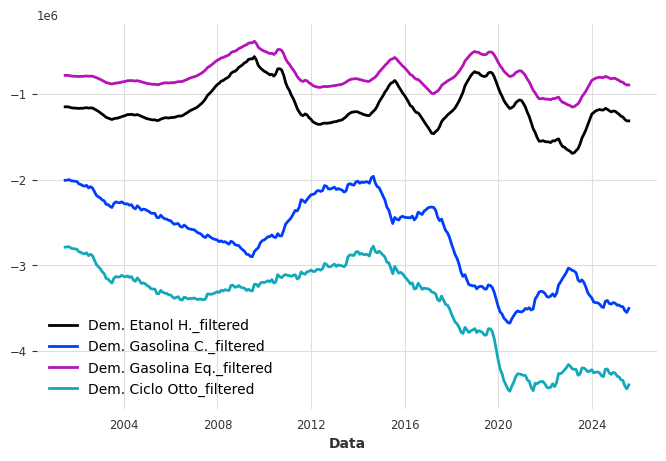

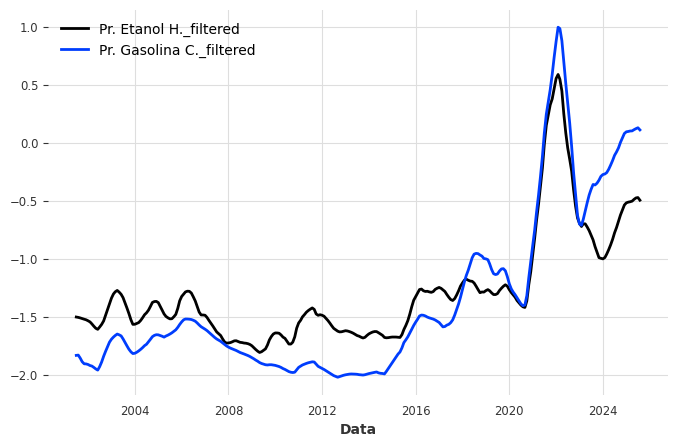

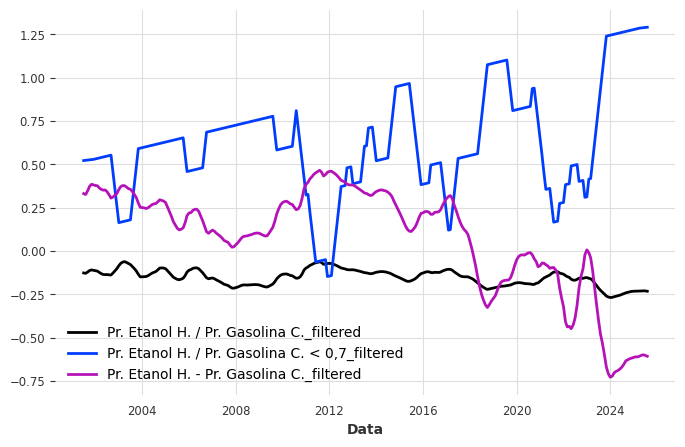

In [26]:
d_etanol_hid_detrend_filtered = d_etanol_hid_detrend.filter()[0]
d_gasolina_com_detrend_filtered = d_gasolina_com_detrend.filter()[0]
d_gasolina_eq_detrend_filtered = d_gasolina_eq_detrend.filter()[0]
d_ciclo_otto_detrend_filtered = d_ciclo_otto_detrend.filter()[0]
p_etanol_hid_detrend_filtered = p_etanol_hid_detrend.filter()[0]
p_gasolina_com_detrend_filtered = p_gasolina_com_detrend.filter()[0]
p_r_etanol_gasolina_detrend_filtered = p_r_etanol_gasolina_detrend.filter()[0]
p_r_etanol_gasolina_bool_detrend_filtered = p_r_etanol_gasolina_bool_detrend.filter()[0]
p_d_etanol_gasolina_detrend_filtered = p_d_etanol_gasolina_detrend.filter()[0]

plot_series(
    [
        d_etanol_hid_detrend_filtered,
        d_gasolina_com_detrend_filtered,
        d_gasolina_eq_detrend_filtered,
        d_ciclo_otto_detrend_filtered,
    ],
)
plot_series(
    [
        p_etanol_hid_detrend_filtered,
        p_gasolina_com_detrend_filtered,
    ],
)

plot_series(
    [
        p_r_etanol_gasolina_detrend_filtered,
        p_r_etanol_gasolina_bool_detrend_filtered,
        p_d_etanol_gasolina_detrend_filtered,
    ],
)

# Treinando o modelo

## Arima

### Original

pmdarima não instalado — instale com `pip install pmdarima` para auto_arima


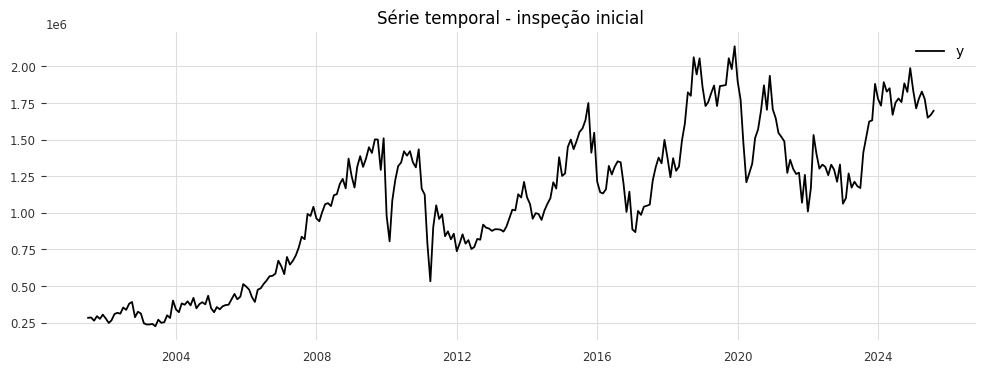

=== ADF test ===
ADF statistic: -1.834103
p-value: 0.363667
Critical value (1%): -3.454355
Critical value (5%): -2.872108
Critical value (10%): -2.572401

=== KPSS test ===
KPSS statistic: 2.076957
p-value: 0.010000
Critical value (10%): 0.347000
Critical value (5%): 0.463000
Critical value (2.5%): 0.574000
Critical value (1%): 0.739000

--- d = 0 ---
ADF p-value: 0.3636665734585845
KPSS p-value: 0.01

--- d = 1 ---
ADF p-value: 0.0035995761134969017
KPSS p-value: 0.1

Diferença necessária (d): 1


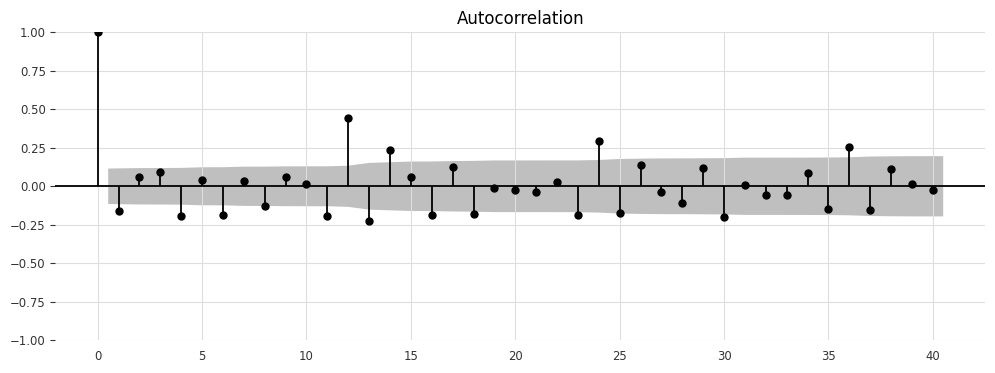

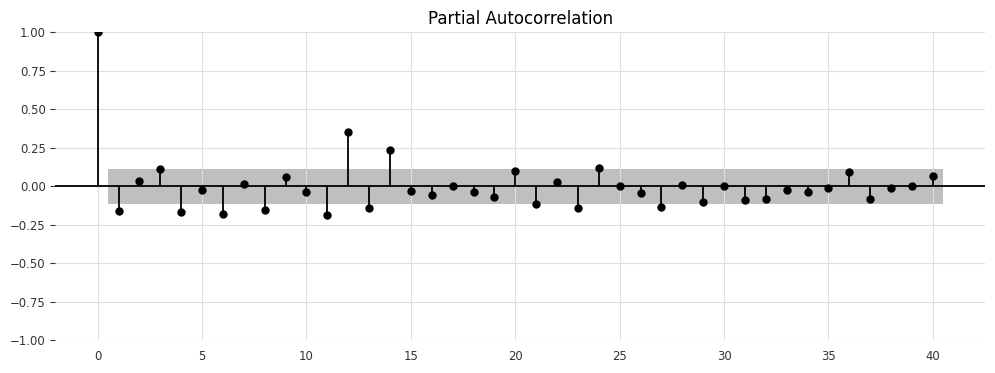

pmdarima não disponível — sugerindo ordem simples: (1, 1, 1)
Treinando SARIMAX(order=(1,1,1), seasonal_order=(0, 0, 0, 0)) ...
                               SARIMAX Results                                
Dep. Variable:         Dem. Etanol H.   No. Observations:                  290
Model:               SARIMAX(1, 1, 1)   Log Likelihood               -3748.976
Date:                Wed, 29 Oct 2025   AIC                           7503.953
Time:                        22:24:08   BIC                           7514.931
Sample:                    07-01-2001   HQIC                          7508.353
                         - 08-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2398      0.234     -1.025      0.305      -0.698       0.219
ma.L

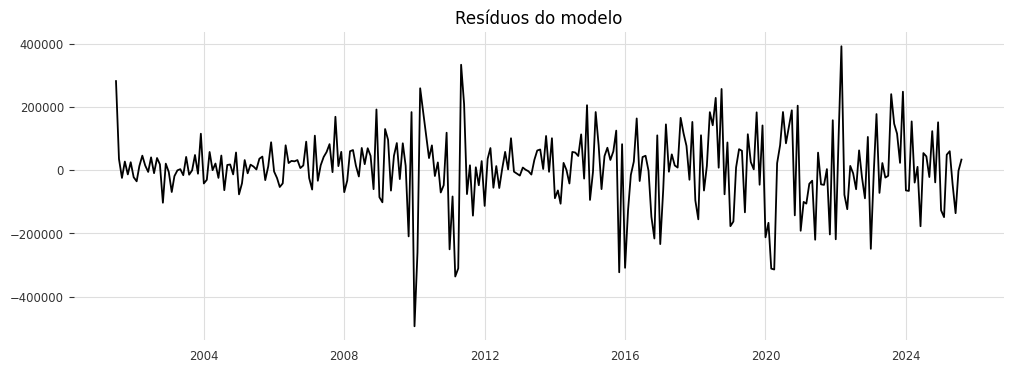

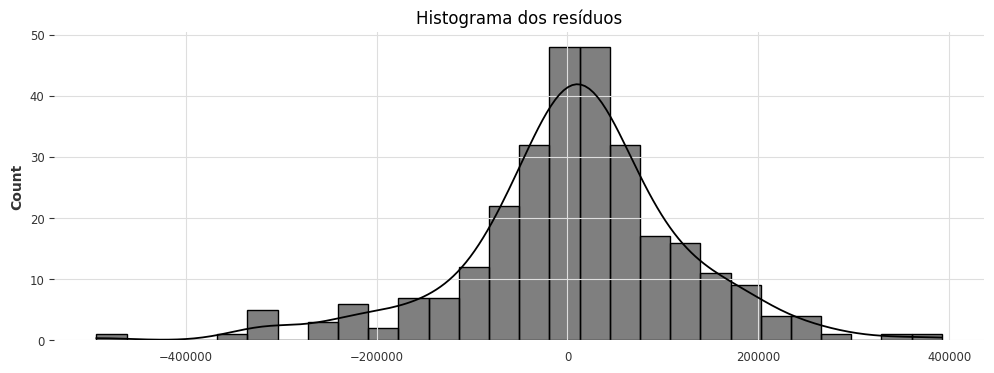

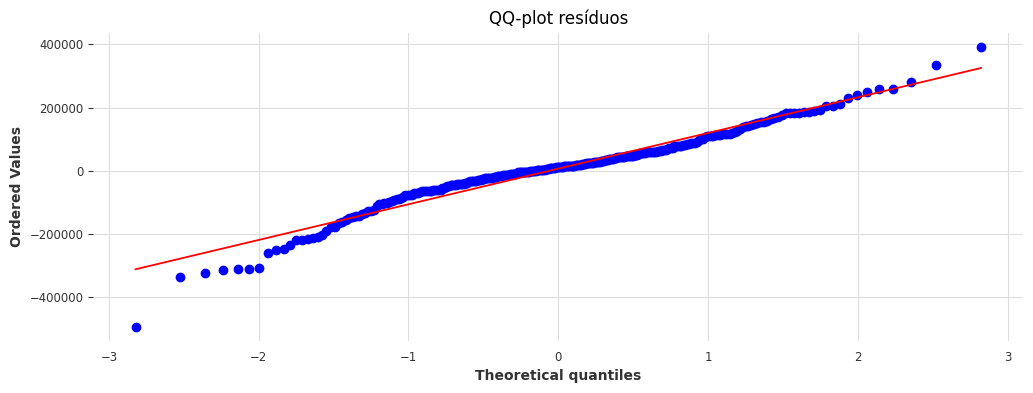


Ljung-Box:
        lb_stat     lb_pvalue
10   25.948357  3.810267e-03
20  118.699831  4.961651e-16

Resíduos: mean: 6642.664452496314  std: 114616.52784283069
Melhor ordem via grid search: (8, 1, 9) (AIC=5721.02)


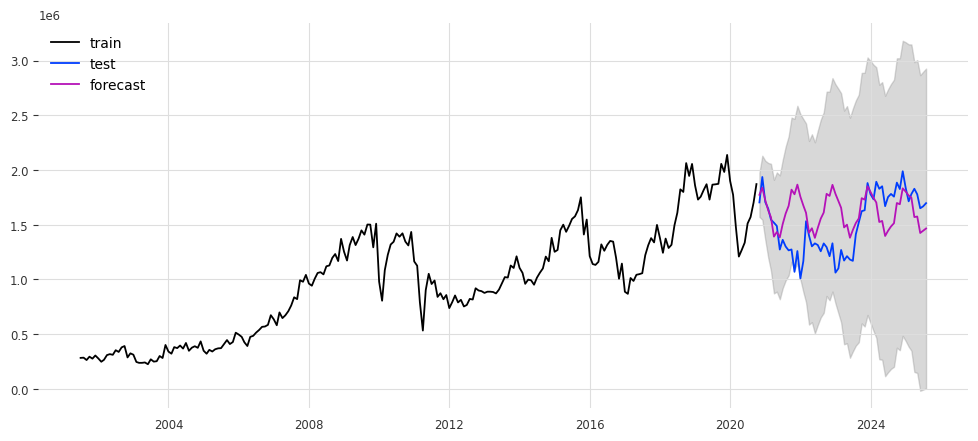

MAE: 241338.3075, RMSE: 311691.2764, MAPE: 18.20%


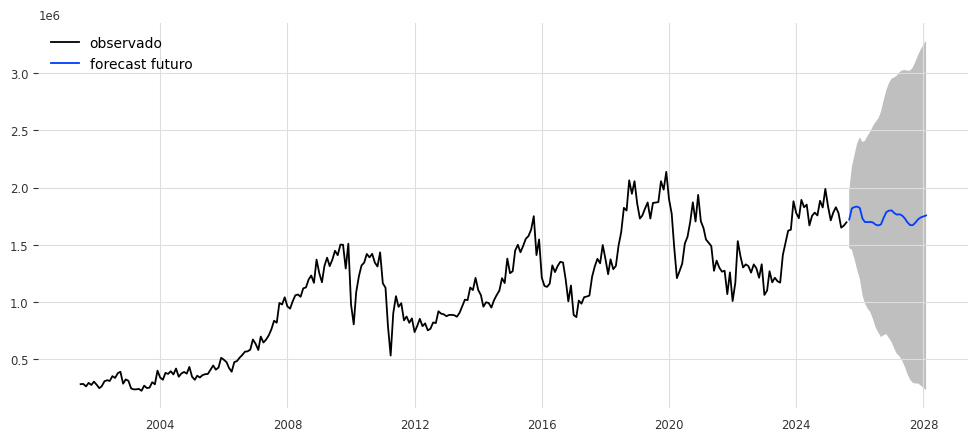

In [31]:
# Requisitos:
# pip install pandas numpy matplotlib seaborn statsmodels pmdarima scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Opcional: auto_arima (busca automática de ordem)
try:
    from pmdarima import auto_arima
    HAS_PMDARIMA = True
except Exception:
    HAS_PMDARIMA = False
    print("pmdarima não instalado — instale com `pip install pmdarima` para auto_arima")

# ---------- Assumindo um DataFrame `df` com índice datetime e coluna 'y' ----------
# Exemplo:
# df = pd.read_csv("serie.csv", parse_dates=["date"], index_col="date")
# df = df.asfreq("D")  # definir frequência se fizer sentido (diária, mensal, ...)
# ----------------------------------------------------------------------------

series = df.set_index('month')['Dem. Etanol H.'].dropna()
try:
    series = series.asfreq(series.index.inferred_freq)
except ValueError:
    print("Could not infer frequency, proceeding without setting frequency.")
    pass


# ---------------- 1) Inspeção inicial ----------------
plt.figure(figsize=(12,4))
plt.plot(series, label='y')
plt.title("Série temporal - inspeção inicial")
plt.legend()
plt.show()

# ---------------- 2) Testes de estacionariedade ----------------
def adf_test(x, autolag='AIC'):
    res = adfuller(x, autolag=autolag)
    print("ADF statistic: {:.6f}".format(res[0]))
    print("p-value: {:.6f}".format(res[1]))
    for k,v in res[4].items():
        print("Critical value ({}): {:.6f}".format(k, v))
    return res

def kpss_test(x, regression='c'):
    res = kpss(x, regression=regression, nlags="auto")
    print("KPSS statistic: {:.6f}".format(res[0]))
    print("p-value: {:.6f}".format(res[1]))
    for k,v in res[3].items():
        print("Critical value ({}): {:.6f}".format(k, v))
    return res

print("=== ADF test ===")
adf_res = adf_test(series)
print("\n=== KPSS test ===")
kpss_res = kpss_test(series)

# Interpretação:
# - ADF: H0 = série tem unit root (não estacionária). p-value < 0.05 -> rejeita H0 -> estacionária.
# - KPSS: H0 = estacionária. p-value < 0.05 -> rejeita H0 -> NÃO estacionária.
# Use ambos para robustez.

# ---------------- 3) Se necessário, diferenciar até estacionarizar ----------------
def difference_until_stationary(x, max_d=3):
    d = 0
    x_curr = x.copy()
    for i in range(max_d+1):
        print(f"\n--- d = {d} ---")
        # Check for sufficient observations before testing
        if len(x_curr) < 8: # ADF requires at least 8 observations
             print("Not enough observations for ADF test.")
             break
        print("ADF p-value:", adfuller(x_curr)[1])
        print("KPSS p-value:", kpss(x_curr)[1])
        # se ADF p < 0.05 e KPSS p > 0.05 -> ok estacionária
        if adfuller(x_curr)[1] < 0.05 and kpss(x_curr)[1] > 0.05:
            break
        x_curr = x_curr.diff().dropna()
        d += 1
    return d, x_curr

d_opt, series_diffed = difference_until_stationary(series, max_d=3)
print("\nDiferença necessária (d):", d_opt)

# ---------------- 4) ACF / PACF para sugestão de p e q ----------------
plt.figure(figsize=(12,4))
plot_acf(series_diffed, lags=40, ax=plt.gca())
plt.show()

plt.figure(figsize=(12,4))
plot_pacf(series_diffed, lags=40, ax=plt.gca(), method="ywm")
plt.show()

# Interpretação rápida:
# - p (AR) sugere por quantos lags o PACF tem corte significativo.
# - q (MA) sugere por quantos lags o ACF tem corte significativo.
# Mas usar auto_arima ou grid search também é comum.

# ---------------- 5) Buscar hiperparâmetros (opcional: auto_arima) ----------------
if HAS_PMDARIMA:
    print("Executando auto_arima para sugerir p,d,q (pode demorar)...")
    am = auto_arima(series, start_p=0, start_q=0, max_p=5, max_q=5, d=None,
                    seasonal=False, stepwise=True, trace=True, error_action='ignore', suppress_warnings=True)
    print("auto_arima order:", am.order)
    suggested_order = am.order
else:
    # fallback: use d_opt and try alguns combos simples
    suggested_order = (1, d_opt if d_opt<=2 else 1, 1)
    print("pmdarima não disponível — sugerindo ordem simples:", suggested_order)

p, d, q = suggested_order

# ---------------- 6) Treinar ARIMA / SARIMAX ----------------
# Se houver sazonalidade conhecida (ex: mensal com s=12), usar seasonal_order=(P,D,Q,s)
seasonal = False
seasonal_order = (0,0,0,0)
# Exemplo: if monthly seasonal period 12 -> seasonal=True ; seasonal_order=(1,1,1,12)

print(f"Treinando SARIMAX(order=({p},{d},{q}), seasonal_order={seasonal_order}) ...")
model = SARIMAX(series, order=(p,d,q), seasonal_order=seasonal_order, enforce_stationarity=False, enforce_invertibility=False)
res = model.fit(disp=False)
print(res.summary())

# ---------------- 7) Diagnóstico de resíduos ----------------
residuals = res.resid.dropna()

plt.figure(figsize=(12,4))
plt.plot(residuals)
plt.title("Resíduos do modelo")
plt.show()

plt.figure(figsize=(12,4))
sns.histplot(residuals, kde=True)
plt.title("Histograma dos resíduos")
plt.show()

plt.figure(figsize=(12,4))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("QQ-plot resíduos")
plt.show()

# Autocorrelação dos resíduos (Ljung-Box)
lb_test = acorr_ljungbox(residuals, lags=[10,20], return_df=True)
print("\nLjung-Box:\n", lb_test)

# Verificar média ~ 0 e variância constante:
print("\nResíduos: mean:", residuals.mean(), " std:", residuals.std())

# ---------------- 8) Validação / Hold-out e previsões ----------------
# Separar treino/test (ex: últimos 20 pontos como teste)
n_test = max(10, int(0.2*len(series)))  # ou escolha fixa
train = series.iloc[:-n_test]
test = series.iloc[-n_test:]

import itertools
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

p_values = range(0, 10)  # testar p=0,1,2,3
q_values = range(0, 10)  # testar q=0,1,2,3
d = d_opt

best_aic = np.inf
best_order = None
best_model = None

for p, q in itertools.product(p_values, q_values):
    try:
        model = SARIMAX(train, order=(p,d,q), enforce_stationarity=False, enforce_invertibility=False)
        results = model.fit(disp=False)
        if results.aic < best_aic:
            best_aic = results.aic
            best_order = (p,d,q)
            best_model = results
    except:
        continue

print(f"Melhor ordem via grid search: {best_order} (AIC={best_aic:.2f})")


model_train = SARIMAX(train, order=(best_order[0], best_order[1], best_order[2]), seasonal_order=seasonal_order, enforce_stationarity=False, enforce_invertibility=False)
res_train = model_train.fit(disp=False)

# Forecast
forecast_res = res_train.get_forecast(steps=n_test)
y_pred = forecast_res.predicted_mean
y_pred_ci = forecast_res.conf_int()

# Plot
plt.figure(figsize=(12,5))
plt.plot(train.index, train, label="train")
plt.plot(test.index, test, label="test")
plt.plot(y_pred.index, y_pred, label="forecast")
plt.fill_between(y_pred_ci.index, y_pred_ci.iloc[:,0], y_pred_ci.iloc[:,1], color='gray', alpha=0.3)
plt.legend()
plt.show()

# Métricas
mae = mean_absolute_error(test, y_pred)
rmse = np.sqrt(mean_squared_error(test, y_pred))
mape = np.mean(np.abs((test - y_pred) / test)) * 100

print(f"MAE: {mae:.4f}, RMSE: {rmse:.4f}, MAPE: {mape:.2f}%")

# ---------------- 9) Forecast futuro com tudo ----------------
horizon = 30  # previsões para 30 passos
final_model = SARIMAX(series, order=(p,d,q), seasonal_order=seasonal_order, enforce_stationarity=False, enforce_invertibility=False)
final_res = final_model.fit(disp=False)
fc = final_res.get_forecast(steps=horizon)
fc_mean = fc.predicted_mean
fc_ci = fc.conf_int()

plt.figure(figsize=(12,5))
plt.plot(series.index, series, label='observado')
plt.plot(fc_mean.index, fc_mean, label='forecast futuro')
plt.fill_between(fc_ci.index, fc_ci.iloc[:,0], fc_ci.iloc[:,1], alpha=0.25)
plt.legend()
plt.show()

In [28]:
import itertools
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

p_values = range(0, 4)  # testar p=0,1,2,3
q_values = range(0, 4)  # testar q=0,1,2,3
d = d_opt

best_aic = np.inf
best_order = None
best_model = None

for p, q in itertools.product(p_values, q_values):
    try:
        model = SARIMAX(series, order=(p,d,q), enforce_stationarity=False, enforce_invertibility=False)
        results = model.fit(disp=False)
        if results.aic < best_aic:
            best_aic = results.aic
            best_order = (p,d,q)
            best_model = results
    except:
        continue

print(f"Melhor ordem via grid search: {best_order} (AIC={best_aic:.2f})")


Melhor ordem via grid search: (3, 1, 3) (AIC=7418.51)


In [29]:
p, d, q = best_order

final_model = SARIMAX(series, order=(p,d,q), seasonal_order=(0,0,0,0),
                      enforce_stationarity=False, enforce_invertibility=False)
final_res = final_model.fit(disp=False)

print(final_res.summary())


                               SARIMAX Results                                
Dep. Variable:         Dem. Etanol H.   No. Observations:                  290
Model:               SARIMAX(3, 1, 3)   Log Likelihood               -3702.256
Date:                Wed, 29 Oct 2025   AIC                           7418.511
Time:                        22:13:56   BIC                           7444.078
Sample:                    07-01-2001   HQIC                          7428.760
                         - 08-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7802      0.031    -25.442      0.000      -0.840      -0.720
ar.L2          0.6259      0.044     14.303      0.000       0.540       0.712
ar.L3          0.9272      0.030     30.611      0.0

### Filtrada

In [33]:
scaler = Scaler()
train_scaled = scaler.fit_transform(train)
val_scaled = scaler.transform(val)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid)
d_etanol_hid_scaled = d_etanol_hid_scaled.filter()[0]
train_scaled, val_scaled, test_scaled = d_etanol_hid_scaled.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)

model_name = 'ARIMA'
series_train=['train_filtered_scaled']

for p in range(12, 30, 4):
    for d in range(1, 3):
        for q in range(0, 5, 2):
            for s in range(0, 10, 3):
                try:
                    model_run, existing = create_or_get_model_run(
                        model_name=model_name,
                        parametros={
                            'p': p,
                            'd': d,
                            'q': q,
                            's': s
                        },
                        series_train=series_train
                    )
                    if existing:
                        continue
                    model = ARIMA(
                        p=p,
                        d=d,
                        seasonal_order=(
                            0,
                            0,
                            q,
                            s
                        ),
                    )
                    model.fit(train_scaled)
                    pred_series, mape_arima, sle_arima = eval_model(
                        model,
                        len(val_scaled),
                        d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
                        val_scaled,
                        returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
                        plot = False,
                    )
                    uTheil = UTheil()
                    u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    print({
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                        'p': p,
                        'd': d,
                        'q': q,
                        's': s,
                    })
                    metrics = {
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                    }
                    update_model_metrics(model_run, **metrics)
                except:
                    pass

A saída de streaming foi truncada nas últimas 5000 linhas.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of range.
ERROR:darts.timeseries:IndexError: Integer index out of ran

{'mape': np.float64(16.884804705314046), 'sle': inf, 'u1': np.float64(0.15564647857553407), 'u2': np.float64(0.15564647857553407), 'p': 20, 'd': 1, 'q': 4, 's': 6}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


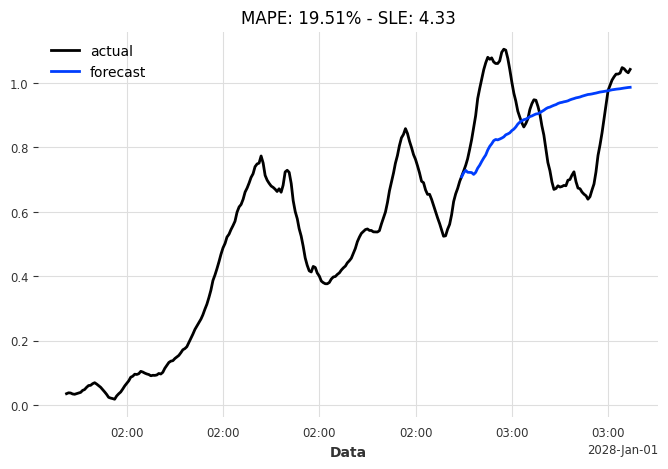

{'p': 12, 'd': 1, 'q': 2, 's': 0}


In [ ]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("ARIMA", series_train=["train_filtered_scaled"], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

scaler = Scaler()
train_scaled = scaler.fit_transform(train)
val_scaled = scaler.transform(val)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid)
d_etanol_hid_scaled = d_etanol_hid_scaled.filter()[0]
train_scaled, val_scaled, test_scaled = d_etanol_hid_scaled.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)

model = ARIMA(
    p=best_model['p'],
    d=best_model['d'],
    seasonal_order=(
        0,
        0,
        best_model['q'],
        3
    ),
)
model.fit(train_scaled)
pred_series, mape_arima, sle_arima = eval_model(
    model,
    len(val_scaled),
    d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
    val_scaled,
    returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
    plot = True,
)
uTheil = UTheil()
u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
print(best_model)

### Sem tendência

In [ ]:
scaler = Scaler()
train_scaled = scaler.fit_transform(train_detrend)
val_scaled = scaler.transform(val_detrend)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid_detrend)

model_name = 'ARIMA'
series_train=['train_detrend_scaled']

for p in range(12, 30, 4):
    for d in range(1, 3):
        for q in range(0, 5, 2):
            for s in range(0, 10, 3):
                try:
                    model_run, existing = create_or_get_model_run(
                        model_name=model_name,
                        parametros={
                            'p': p,
                            'd': d,
                            'q': q,
                            's': s
                        },
                        series_train=series_train
                    )
                    if existing:
                        continue
                    model = ARIMA(
                        p=p,
                        d=d,
                        seasonal_order=(
                            0,
                            0,
                            q,
                            s
                        ),
                    )
                    model.fit(train_scaled)
                    pred_series, mape_arima, sle_arima = eval_model(
                        model,
                        len(val_scaled),
                        d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
                        val_scaled,
                        returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
                        plot = False,
                    )
                    uTheil = UTheil()
                    u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    print({
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                        'p': p,
                        'd': d,
                        'q': q,
                        's': s,
                    })
                    metrics = {
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                    }
                    update_model_metrics(model_run, **metrics)
                except:
                    pass

{'mape': np.float64(212.4720243488965), 'sle': np.float64(90.5571482554552), 'u1': np.float64(0.5162831085919465), 'u2': np.float64(0.5162831085919465), 'p': 12, 'd': 1, 'q': 0, 's': 0}
{'mape': np.float64(212.4720243488965), 'sle': np.float64(90.5571482554552), 'u1': np.float64(0.5162831085919465), 'u2': np.float64(0.5162831085919465), 'p': 12, 'd': 1, 'q': 0, 's': 3}
{'mape': np.float64(212.4720243488965), 'sle': np.float64(90.5571482554552), 'u1': np.float64(0.5162831085919465), 'u2': np.float64(0.5162831085919465), 'p': 12, 'd': 1, 'q': 0, 's': 6}
{'mape': np.float64(212.4720243488965), 'sle': np.float64(90.5571482554552), 'u1': np.float64(0.5162831085919465), 'u2': np.float64(0.5162831085919465), 'p': 12, 'd': 1, 'q': 0, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(216.1341642198263), 'sle': np.float64(91.14881379483718), 'u1': np.float64(0.5101140396664884), 'u2': np.float64(0.5101140396664884), 'p': 12, 'd': 1, 'q': 2, 's': 3}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(228.35109726550792), 'sle': np.float64(94.65510999653698), 'u1': np.float64(0.4984364034246259), 'u2': np.float64(0.4984364034246259), 'p': 12, 'd': 1, 'q': 2, 's': 6}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (101 outputs left out)

/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(205.02808442253885), 'sle': np.float64(90.26016965454063), 'u1': np.float64(0.5382843417915435), 'u2': np.float64(0.5382843417915435), 'p': 24, 'd': 2, 'q': 2, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(250.2098475406684), 'sle': np.float64(99.64588069326292), 'u1': np.float64(0.47096829062958484), 'u2': np.float64(0.47096829062958484), 'p': 28, 'd': 1, 'q': 0, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


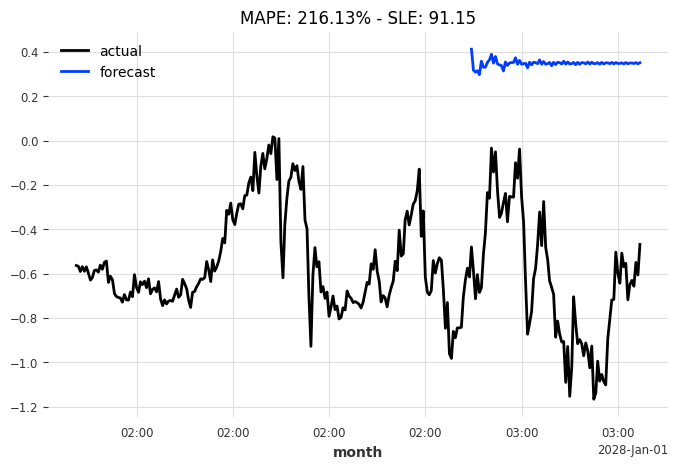

{'p': 12, 'd': 1, 'q': 2, 's': 0}


In [ ]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("ARIMA", series_train=["train_detrend_scaled"], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

scaler = Scaler()
train_scaled = scaler.fit_transform(train_detrend)
val_scaled = scaler.transform(val_detrend)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid_detrend)

model = ARIMA(
    p=best_model['p'],
    d=best_model['d'],
    seasonal_order=(
        0,
        0,
        best_model['q'],
        3
    ),
)
model.fit(train_scaled)
pred_series, mape_arima, sle_arima = eval_model(
    model,
    len(val_scaled),
    d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
    val_scaled,
    returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
    plot = True,
)
uTheil = UTheil()
u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
print(best_model)

### Filtrada e sem tendência

In [ ]:
scaler = Scaler()
train_scaled = scaler.fit_transform(train_detrend)
val_scaled = scaler.transform(val_detrend)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid_detrend)
d_etanol_hid_scaled = d_etanol_hid_scaled.filter()[0]
train_scaled, val_scaled, test_scaled = d_etanol_hid_scaled.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)

model_name = 'ARIMA'
series_train=['train_detrend_scaled_filtered']

for p in range(12, 30, 4):
    for d in range(1, 3):
        for q in range(0, 5, 2):
            for s in range(0, 10, 3):
                try:
                    model_run, existing = create_or_get_model_run(
                        model_name=model_name,
                        parametros={
                            'p': p,
                            'd': d,
                            'q': q,
                            's': s
                        },
                        series_train=series_train
                    )
                    if existing:
                        continue
                    model = ARIMA(
                        p=p,
                        d=d,
                        seasonal_order=(
                            0,
                            0,
                            q,
                            s
                        ),
                    )
                    model.fit(train_scaled)
                    pred_series, mape_arima, sle_arima = eval_model(
                        model,
                        len(val_scaled),
                        d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
                        val_scaled,
                        returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
                        plot = False,
                    )
                    uTheil = UTheil()
                    u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
                    print({
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                        'p': p,
                        'd': d,
                        'q': q,
                        's': s,
                    })
                    metrics = {
                        'mape': mape_arima,
                        'sle': sle_arima,
                        'u1': u1_arima,
                        'u2': u1_arima,
                    }
                    update_model_metrics(model_run, **metrics)
                except:
                    pass

{'mape': np.float64(47.9329055065423), 'sle': np.float64(20.986991849914567), 'u1': np.float64(0.2897013403144119), 'u2': np.float64(0.2897013403144119), 'p': 12, 'd': 1, 'q': 0, 's': 0}
{'mape': np.float64(47.9329055065423), 'sle': np.float64(20.986991849914567), 'u1': np.float64(0.2897013403144119), 'u2': np.float64(0.2897013403144119), 'p': 12, 'd': 1, 'q': 0, 's': 3}
{'mape': np.float64(47.9329055065423), 'sle': np.float64(20.986991849914567), 'u1': np.float64(0.2897013403144119), 'u2': np.float64(0.2897013403144119), 'p': 12, 'd': 1, 'q': 0, 's': 6}
{'mape': np.float64(47.9329055065423), 'sle': np.float64(20.986991849914567), 'u1': np.float64(0.2897013403144119), 'u2': np.float64(0.2897013403144119), 'p': 12, 'd': 1, 'q': 0, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(48.659683373154564), 'sle': np.float64(22.990403754053666), 'u1': np.float64(0.32731521667942015), 'u2': np.float64(0.32731521667942015), 'p': 12, 'd': 1, 'q': 2, 's': 3}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(47.17795050500058), 'sle': np.float64(20.57433878052202), 'u1': np.float64(0.2877852219726024), 'u2': np.float64(0.2877852219726024), 'p': 12, 'd': 1, 'q': 2, 's': 6}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'


... (102 outputs left out)

{'mape': np.float64(51.568585434500754), 'sle': np.float64(23.103359064703483), 'u1': np.float64(0.30804165149729185), 'u2': np.float64(0.30804165149729185), 'p': 28, 'd': 2, 'q': 4, 's': 3}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


{'mape': np.float64(52.45662564441475), 'sle': np.float64(22.79724210629336), 'u1': np.float64(0.28573111749066404), 'u2': np.float64(0.28573111749066404), 'p': 28, 'd': 2, 'q': 4, 's': 6}
{'mape': np.float64(50.591561100357104), 'sle': np.float64(25.536079487379418), 'u1': np.float64(0.35466405330923395), 'u2': np.float64(0.35466405330923395), 'p': 28, 'd': 2, 'q': 4, 's': 9}


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


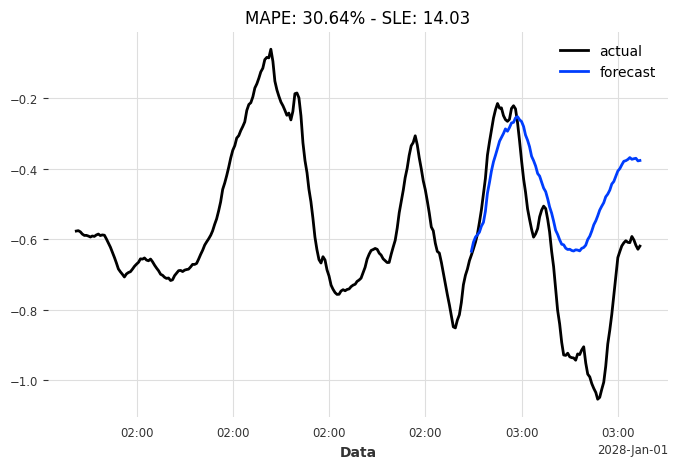

{'p': 28, 'd': 1, 'q': 2, 's': 3}


In [ ]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("ARIMA", series_train=["train_detrend_scaled_filtered"], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

scaler = Scaler()
train_scaled = scaler.fit_transform(train_detrend)
val_scaled = scaler.transform(val_detrend)
d_etanol_hid_scaled = scaler.transform(d_etanol_hid_detrend)
d_etanol_hid_scaled = d_etanol_hid_scaled.filter()[0]
train_scaled, val_scaled, test_scaled = d_etanol_hid_scaled.split(
    [pd.Timestamp(VAL_START), pd.Timestamp(TEST_START)]
)

model = ARIMA(
    p=best_model['p'],
    d=best_model['d'],
    seasonal_order=(
        0,
        0,
        best_model['q'],
        best_model['s'],
    ),
)
model.fit(train_scaled)
pred_series, mape_arima, sle_arima = eval_model(
    model,
    len(val_scaled),
    d_etanol_hid_scaled.slice(train.start_time(), val.end_time()),
    val_scaled,
    returned = ['PREDICT_VALUES', 'MAPE_VAL', 'SLE_VAL'],
    plot = True,
)
uTheil = UTheil()
u1_arima = uTheil.calculateU1(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
u2_arima = uTheil.calculateU2(val_scaled.values().flatten(), pred_series[:len(val)].values().flatten())
print(best_model)

## NARX

### Etanol

In [ ]:
from tqdm import tqdm
def pred_values(self, val):
        start_time = val.time_index[0]
        date_freq = val.freq
        if not self.fit_called:
            raise RuntimeError("evaluate() was not called before predict()")
        if type(val) == TimeSeries:
            val = val.univariate_values().tolist()
        else:
            raise ValueError("series must be TimeSeries")
        val = self.window_model.embed_time_series(val)
        val_scaled = self.apply_preprocessing(val.copy())

        if self.random_state is not None:
            torch.manual_seed(self.random_state)
            np.random.seed(self.random_state)

        predicted_outputs = []
        predicted_outputs_original = []

        with tqdm(total=len(val), desc="Prediction") as progress_bar:
            for val_l in val:
                output_original = self.predict_window_with_preprocessing(val_l[0])
                predicted_outputs_original.append(output_original)
                output = self.predict_window_with_preprocessing(val_l[0], False)
                predicted_outputs.append(output)
                progress_bar.update(1)

        predicted_outputs_original = np.array(predicted_outputs_original).flatten()
        return TimeSeries.from_times_and_values(pd.date_range(start=start_time, periods=len(predicted_outputs_original) + self.input_chunk_length, freq=date_freq)[self.input_chunk_length:] ,predicted_outputs_original)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:658: Checkpoint directory /home/ellizeu.sena/Documentos/Mestrado/lightning_logs/version_152/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type    | Params | Mode 
--------------------------------------------
0 | loss_fn | MSELoss | 0      | train
1 | lin     | Linear  | 3.6 K  | train
2 | lin2    | Linear  | 262 K  | train
3 | lin3    | Linear  | 1.5 K  | train
4 | tanh    | Tanh    | 0      | train
--------------------------------------------
267 K     Trainable params
0         Non-trainable params
267 

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/loops/fit_loop.py:310: The number of training batches (8) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (197 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


Prediction:   0%|          | 0/26 [00:00<?, ?it/s]

Prediction: 100%|██████████| 26/26 [00:00<00:00, 1519.36it/s]


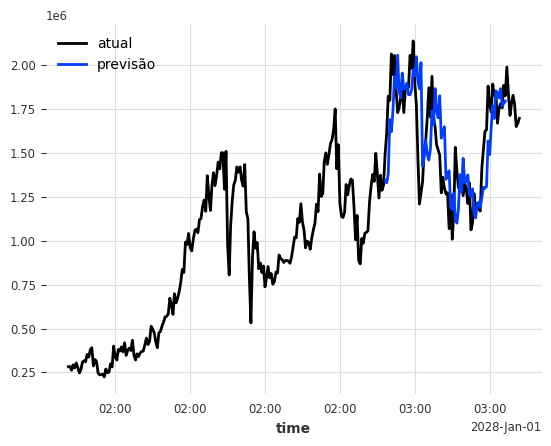

{'mape': 0.11486358593400536, 'sle': np.float64(1.7051234475686443), 'rmse': 225397.9361353283, 'mse': 51659386494.3993, 'u1': np.float64(0.6566406315214249), 'u2': np.float64(0.26274449471387623), 'input_chunk_length': 6, 'output_chunk_length': 3, 'hidden_size': 9, 'batch_size': 3, 'lr': 6}


In [ ]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("NARX", series_train=["train_scaled"], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = NARX(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=2**best_model['hidden_size'],
    batch_size=2**best_model['batch_size'],
    n_epochs=200,
    lr=10**(-best_model['lr']),
    preprocessing = [MinMaxScaler()],
    random_state = 0,
)
model.fit(train, val)
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


### Etanal + Preço da gasolina

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:658: Checkpoint directory /home/ellizeu.sena/Documentos/Mestrado/lightning_logs/version_152/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type    | Params | Mode 
--------------------------------------------
0 | loss_fn | MSELoss | 0      | train
1 | lin     | Linear  | 112    | train
2 | lin2    |

Training: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


Prediction:   0%|          | 0/26 [00:00<?, ?it/s]

Prediction: 100%|██████████| 26/26 [00:00<00:00, 1798.20it/s]


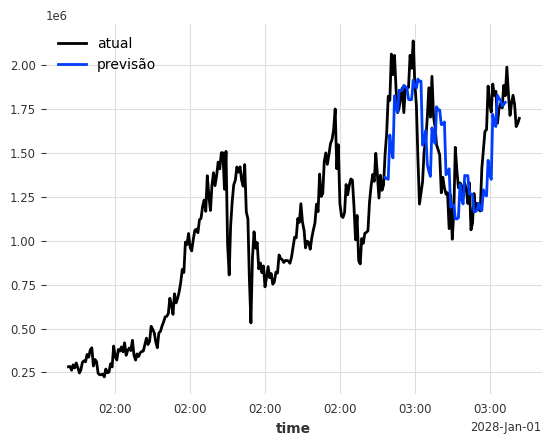

{'mape': 0.12657019693779661, 'sle': np.float64(2.098168705457015), 'rmse': 250684.69277790302, 'mse': 63259275077.309654, 'u1': np.float64(0.7422104963463624), 'u2': np.float64(0.28358171212687117), 'input_chunk_length': 6, 'output_chunk_length': 3, 'hidden_size': 4, 'batch_size': 2, 'lr': 5}


In [ ]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("NARX", series_train=['train_p_gasolina_scaled', 'train_scaled'], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = NARX(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=2**best_model['hidden_size'],
    batch_size=2**best_model['batch_size'],
    n_epochs=200,
    lr=10**(-best_model['lr']),
    preprocessing = [MinMaxScaler()],
    random_state = 0,
)
model.fit([train_p_gasolina, train])
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


### Etanal + Preço da gasolina (detrend)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:658: Checkpoint directory /home/ellizeu.sena/Documentos/Mestrado/lightning_logs/version_152/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type    | Params | Mode 
--------------------------------------------
0 | loss_fn | MSELoss | 0      | train
1 | lin     | Linear  | 112    | train
2 | lin2    |

Training: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


Prediction:   0%|          | 0/26 [00:00<?, ?it/s]

Prediction: 100%|██████████| 26/26 [00:00<00:00, 929.20it/s]


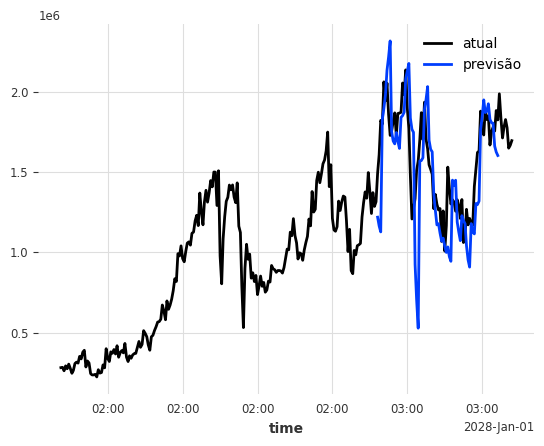

{'mape': 0.1381948621079581, 'sle': np.float64(3.9323867583508916), 'rmse': 274608.26935894525, 'mse': 79959015305.5293, 'u1': np.float64(0.87372168221984), 'u2': np.float64(1.302780710363824), 'input_chunk_length': 6, 'output_chunk_length': 3, 'hidden_size': 4, 'batch_size': 2, 'lr': 5}


In [ ]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("NARX", series_train=['train_p_gasolina_detrend_scaled', 'train_detrend_scaled'], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = NARX(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=2**best_model['hidden_size'],
    batch_size=2**best_model['batch_size'],
    n_epochs=200,
    lr=10**(-best_model['lr']),
    preprocessing = [Detrend(),MinMaxScaler()],
    random_state = 0,
)
model.fit([train_p_gasolina, train])
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


## DA-RNN

### Etanol

In [ ]:
from tqdm import tqdm
def pred_values(self, val):
        start_time = val.time_index[0]
        date_freq = val.freq
        if not self.fit_called:
            raise RuntimeError("evaluate() was not called before predict()")
        if type(val) == TimeSeries:
            val = val.univariate_values().tolist()
        else:
            raise ValueError("series must be TimeSeries")
        val = self.window_model.embed_time_series(val)
        val_scaled = self.apply_preprocessing(val.copy())

        if self.random_state is not None:
            torch.manual_seed(self.random_state)
            np.random.seed(self.random_state)

        predicted_outputs = []
        predicted_outputs_original = []

        with tqdm(total=len(val), desc="Prediction") as progress_bar:
            for val_l in val:
                output_original = self.predict_window_with_preprocessing(val_l[0])
                predicted_outputs_original.append(output_original)
                output = self.predict_window_with_preprocessing(val_l[0], False)
                predicted_outputs.append(output)
                progress_bar.update(1)

        predicted_outputs_original = np.array(predicted_outputs_original).flatten()
        return TimeSeries.from_times_and_values(pd.date_range(start=start_time, periods=len(predicted_outputs_original) + self.input_chunk_length, freq=date_freq)[self.input_chunk_length:] ,predicted_outputs_original)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:658: Checkpoint directory /home/ellizeu.sena/Documentos/Mestrado/lightning_logs/version_156/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type               | Params | Mode 
---------------------------------------------------------
0 | loss_fn   | MSELoss            | 0      | train
1 | rnn       | LSTM               | 512    | train
2 | attention | MultiheadAttention | 288    | train
3 | fc        | Linear             | 27     | train
---------------------------------------------------------
827       

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/loops/fit_loop.py:310: The number of training batches (4) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (197 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


Prediction:   0%|          | 0/26 [00:00<?, ?it/s]

Prediction: 100%|██████████| 26/26 [00:00<00:00, 1175.52it/s]


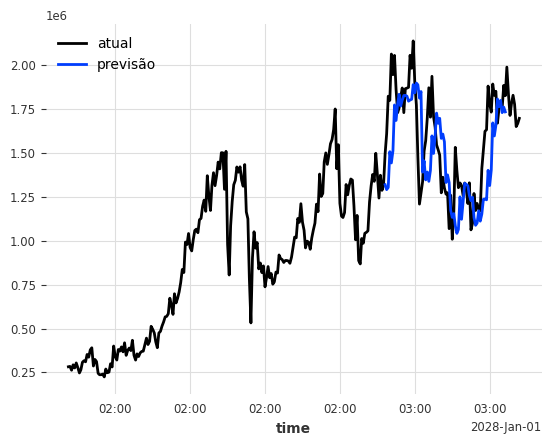

{'mape': 0.12948780108130567, 'sle': np.float64(2.2227922386650167), 'rmse': 255012.49381927564, 'mse': 65394141519.85609, 'u1': np.float64(0.7790869940858488), 'u2': np.float64(0.3463063163145746), 'lr': 0.001, 'input_chunk_length': 6, 'output_chunk_length': 3, 'hidden_size': 8, 'batch_size': 16, 'num_heads_attention': 2, 'dropout': 0.0}


In [ ]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("DA-RNN", series_train=["train_scaled"], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = DA_RNN(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=best_model['hidden_size'],
    batch_size=best_model['batch_size'],
    num_heads_attention=best_model['num_heads_attention'],
    dropout=best_model['dropout'],
    n_epochs=200,
    lr=best_model['lr'],
    preprocessing = [MinMaxScaler()],
    random_state = 0
)
model.fit(train, val)
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


### Etanal + Preço da gasolina

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
/home/ellizeu.sena/Documentos/Mestrado/venv/lib/python3.12/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:658: Checkpoint directory /home/ellizeu.sena/Documentos/Mestrado/lightning_logs/version_156/checkpoints exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type               | Params | Mode 
---------------------------------------------------------
0 | loss_fn   | MSELoss            | 0      | train
1 | rnn      

Training: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


Prediction:   0%|          | 0/26 [00:00<?, ?it/s]

Prediction: 100%|██████████| 26/26 [00:00<00:00, 1170.51it/s]


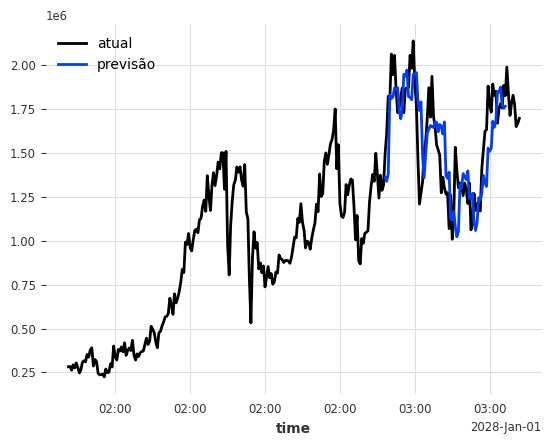

{'mape': 0.11156255477556047, 'sle': np.float64(1.5236577191035516), 'rmse': 206844.16398925838, 'mse': 42861451680.219086, 'u1': np.float64(0.6377428980042497), 'u2': np.float64(0.568717587631542), 'lr': 0.001, 'input_chunk_length': 6, 'output_chunk_length': 3, 'hidden_size': 32, 'batch_size': 16, 'num_heads_attention': 2, 'dropout': 0.0}


In [ ]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("DA-RNN", series_train=['train_p_gasolina_scaled', 'train_scaled'], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = DA_RNN(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=best_model['hidden_size'],
    batch_size=best_model['batch_size'],
    num_heads_attention=best_model['num_heads_attention'],
    dropout=best_model['dropout'],
    n_epochs=200,
    lr=best_model['lr'],
    preprocessing = [MinMaxScaler()],
    random_state = 0
)
model.fit([train_p_gasolina, train])
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


### Etanal + Preço da gasolina (detrend)

In [ ]:
# --- Recuperar o melhor modelo pelo MAPE ---
best_model_run = get_best_model_run("DA-RNN", series_train=['train_p_gasolina_detrend_scaled', 'train_detrend_scaled'], metric="mape")

# Extrair parâmetros
best_model = best_model_run.parametros

model = DA_RNN(
    input_chunk_length=best_model['input_chunk_length'],
    output_chunk_length=best_model['output_chunk_length'],
    hidden_size=best_model['hidden_size'],
    batch_size=best_model['batch_size'],
    num_heads_attention=best_model['num_heads_attention'],
    dropout=best_model['dropout'],
    n_epochs=200,
    lr=best_model['lr'],
    preprocessing = [MinMaxScaler()],
    random_state = 0
)
model.fit([train_p_gasolina, train])
metrics = model.evaluate(val)

d_etanol_hid.plot(label='atual')

# Plot da série de previsão
pred = pred_values(model, val)
pred.plot(label='previsão')
plt.show()

print({
    'mape': metrics['mape'],
    'sle': metrics['sle'],
    'rmse': metrics['rmse'],
    'mse': metrics['mse'],
    'u1': metrics['u1'],
    'u2': metrics['u2'],
    **best_model
})


AttributeError: 'NoneType' object has no attribute 'parametros'